# RuBERT-tiny2: исходный опыт и проверки устойчивости

Исходный seed 42 и четыре обучения seeds 17/123 выполнены на CPU.
По умолчанию читаются сохранённые результаты. Для нового опыта
задайте stability_checks.reuse_fitted_batch=null: четыре обучения.
Вход только operator_log; объединения признаков нет. Разбиение eda_v1
неизменно, test не оценивается. Переформулировки синтетические,
не используются ни для обучения, ни для выбора эпох или порогов.
Повторная настройка по результатам этой проверки не выполняется.


## Окружение и устройство

В следующей ячейке задайте `DEVICE = "cpu"` (локально) или `"cuda"` (NVIDIA). Затем Restart Kernel → Run All. Рабочий каталог — notebooks/experiments; ядро — .venv Python 3.11. CUDA проверяется до загрузки данных; скрытого перехода на CPU нет. Если видны несколько GPU, заранее задайте CUDA_VISIBLE_DEVICES. Оба режима используют один протокол FP32 и два обучения.


In [1]:
import hashlib
import json
import logging
import os
import pickle
import platform
import shutil
import sys
import warnings
from datetime import datetime, timezone
from importlib.metadata import version
from itertools import product
from pathlib import Path
from time import perf_counter

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
PROJECT_ROOT = Path("../..").resolve()
if not (PROJECT_ROOT / "configs/04_rubert_tiny2.json").is_file():
    raise RuntimeError("Рабочий каталог должен быть notebooks/experiments.")
if Path(sys.prefix).resolve() != (PROJECT_ROOT / ".venv").resolve():
    raise RuntimeError("Выберите ядро .venv проекта.")
if sys.version_info[:2] != (3, 11):
    raise RuntimeError("Нужен Python 3.11.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.environ.setdefault("HF_HOME", str(PROJECT_ROOT / ".cache/huggingface"))

'C:\\Users\\Mo\\work\\study\\Магистратура\\2к\\1с\\LLMs\\.cache\\huggingface'

In [2]:
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from scipy.special import softmax
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
    confusion_matrix,
)
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

from industrial_maintenance import baseline, data, text_transformer
from industrial_maintenance.comparison import paired_group_bootstrap
from industrial_maintenance.wording_checks import (
    validate_wording_pairs,
    wording_prediction_table,
)

DEVICE = "cpu"  # На сервере замените на "cuda" перед Run All.

CONFIG = json.loads(
    (PROJECT_ROOT / "configs/04_rubert_tiny2.json").read_text(encoding="utf-8")
)
CONFIG["execution"]["device"] = DEVICE
hardware = text_transformer.configure_execution(
    DEVICE, CONFIG["execution"]["cpu_threads"]
)
display(hardware)
assert CONFIG["features"] == ["operator_log"]
assert CONFIG["expected_training_runs"] == (
    len(CONFIG["targets"]) * len(CONFIG["stability_checks"]["seeds"])
)
versions = {
    name: version(name)
    for name in [
        "torch",
        "transformers",
        "accelerate",
        "numpy",
        "pandas",
        "scikit-learn",
        "mlflow",
        "scipy",
    ]
}
display(CONFIG)
display(pd.Series(versions, name="Версия"))

C:\Users\Mo\work\study\Магистратура\2к\1с\LLMs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/18 15:03:08 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\Mo\work\study\Магистратура\2к\1с\LLMs\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


{'device': 'cpu',
 'cpu_threads': 6,
 'logical_cpus': 12,
 'cuda_build': None,
 'gpu': None,
 'gpu_bytes': None}

{'model_id': 'cointegrated/rubert-tiny2',
 'notebook': 'notebooks/experiments/04_rubert_tiny2.ipynb',
 'revision': 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae',
 'features': ['operator_log'],
 'excluded_features': ['required_route',
  'severity',
  'id',
  'failure_within_30d',
  'fault_type'],
 'dataset_config': 'configs/eda_16_10.json',
 'membership_file': 'Data/splits/eda_v1/membership.csv',
 'split_manifest': 'Data/splits/eda_v1/manifest.json',
 'membership_sha256': '7df958804864a5e37776843f66ab7ab358b74a685188df14f60eb83cddea00b1',
 'expected_sizes': {'train': 10655, 'validation': 2193, 'test': 2152},
 'targets': {'failure_within_30d': 'average_precision',
  'fault_type': 'macro_f1'},
 'expected_classes': {'failure_within_30d': [0, 1],
  'fault_type': ['bearing_wear',
   'cavitation',
   'imbalance',
   'normal',
   'overheat',
   'seal_leak']},
 'expected_training_runs': 4,
 'max_length': 128,
 'seed': 42,
 'execution': {'device': 'cpu', 'cpu_threads': 6},
 'training': {'learning_r

torch           2.9.1+cpu
transformers       4.57.6
accelerate         1.12.0
numpy               2.4.6
pandas              3.0.6
scikit-learn        1.9.1
mlflow             3.17.1
scipy              1.17.1
Name: Версия, dtype: str

## 2. Неизменяемые данные и только train/validation

Полный CSV читается для проверки контрольной суммы и разбиения.
После проверки test не передаётся ни в токенизацию, ни в обучение,
ни в оценивание. Исходные журналы не очищаются и не маскируются.

In [3]:
dataset_config = json.loads(
    (PROJECT_ROOT / CONFIG["dataset_config"]).read_text(encoding="utf-8")
)
frame, source_manifest = data.load_dataset(PROJECT_ROOT, dataset_config)
membership_path = PROJECT_ROOT / CONFIG["membership_file"]
assert data.file_sha256(membership_path) == CONFIG["membership_sha256"]
split_manifest = json.loads(
    (PROJECT_ROOT / CONFIG["split_manifest"]).read_text(encoding="utf-8")
)
assert split_manifest["protocol"]["sha256"] == source_manifest["sha256"]
assert split_manifest["membership_sha256"] == CONFIG["membership_sha256"]
assert split_manifest["sizes"] == CONFIG["expected_sizes"]
membership = pd.read_csv(membership_path, dtype={"id": "string"})
data.validate_splits(frame, membership)
parts = {}
for split in ["train", "validation"]:
    ids = membership.loc[membership["split"].eq(split), "id"]
    parts[split] = frame.loc[frame["id"].isin(ids)].copy()
    assert len(parts[split]) == CONFIG["expected_sizes"][split]
del frame
train, validation = parts["train"], parts["validation"]
for target, expected_classes in CONFIG["expected_classes"].items():
    assert sorted(train[target].unique().tolist()) == expected_classes
    assert set(validation[target]).issubset(set(expected_classes))
    display(
        pd.DataFrame(
            {
                "train": train[target].value_counts(),
                "validation": validation[target].value_counts(),
            }
        )
    )
display(pd.Series(split_manifest["sizes"], name="Размер выборки"))

,train,validation
failure_within_30d,,
0,8870,1830
1,1785,363


,train,validation
fault_type,,
bearing_wear,1261,255
cavitation,1069,222
imbalance,1147,232
normal,4783,1005
overheat,1215,252
seal_leak,1180,227


train         10655
validation     2193
test           2152
Name: Размер выборки, dtype: int64

## 3. Закреплённые контроли и соответствие id

Читаем TF-IDF, числовой CatBoost и prior из явно указанных запусков.
Модели не переобучаются, их файлы и MLflow не изменяются.
TF-IDF имеет те же входы; CatBoost получает другую информацию.

In [4]:
references = {}
reference_checksums = {}
for reference in CONFIG["references"]:
    batch = PROJECT_ROOT / reference["batch"]
    reference_manifest = json.loads(
        (batch / "manifest.json").read_text(encoding="utf-8")
    )
    assert reference_manifest["status"] == "completed"
    assert not reference_manifest["test_evaluated"]
    assert reference_manifest["source"]["sha256"] == source_manifest["sha256"]
    assert (
        reference_manifest["config"]["membership_sha256"]
        == CONFIG["membership_sha256"]
    )
    assert reference_manifest["split"]["sizes"] == split_manifest["sizes"]
    selected = pd.read_csv(batch / reference["table"])
    selected = selected.loc[selected["variant"].eq(reference["variant"])]
    assert len(selected) == 2
    paths = [batch / "manifest.json", batch / reference["table"]]
    for row in selected.to_dict("records"):
        target = row["target"]
        directory = PROJECT_ROOT / row["run_path"]
        trial = json.loads(
            (directory / "manifest.json").read_text(encoding="utf-8")
        )
        assert sorted(trial["classes"]) == CONFIG["expected_classes"][target]
        assert not set(CONFIG["excluded_features"]).intersection(
            trial["features"]
        )
        predictions = pd.read_csv(
            directory / "validation_predictions.csv",
            dtype={"id": "string"},
            float_precision="round_trip",
        )
        truth = validation.set_index("id")[target]
        assert predictions.id.is_unique
        assert set(predictions.id) == set(truth.index)
        np.testing.assert_array_equal(
            predictions.set_index("id").loc[truth.index, "y_true"], truth
        )
        references[(reference["name"], target)] = {
            "predictions": predictions,
            "directory": directory,
        }
        paths.extend(
            [
                directory / "manifest.json",
                directory / "validation_predictions.csv",
            ]
        )
        if target == "failure_within_30d":
            paths.append(directory / "validation_predictions_f2.csv")
    for path in paths:
        reference_checksums[path.relative_to(PROJECT_ROOT).as_posix()] = (
            data.file_sha256(path)
        )
display(
    pd.DataFrame(
        [
            {
                "control": name,
                "target": target,
                **baseline.classification_metrics(
                    item["predictions"],
                    CONFIG["expected_classes"][target],
                    target,
                ),
            }
            for (name, target), item in references.items()
        ]
    )
)

,control,target,accuracy,macro_f1,log_loss,precision,recall,f1,f2,roc_auc,average_precision
0,tfidf,failure_within_30d,0.832649,0.500820,0.313482,0.452381,0.052342,0.093827,0.063588,0.855282,0.442193
1,tfidf,fault_type,1.000000,1.000000,0.043574,NaN,NaN,NaN,NaN,NaN,NaN
2,catboost_numeric,failure_within_30d,0.892841,0.795255,0.203937,0.702532,0.611570,0.653903,0.627828,0.948259,0.786742
3,catboost_numeric,fault_type,0.807570,0.757161,0.461973,NaN,NaN,NaN,NaN,NaN,NaN
4,prior,failure_within_30d,0.834473,0.454884,0.448736,0.000000,0.000000,0.000000,0.000000,0.500000,0.165527
5,prior,fault_type,0.458276,0.104753,1.561055,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Готовый токенизатор и длина последовательности

Словарь не обучается на наших данных. Ограничение 128 проверяем на train;
если оно обрезает тексты, эксперимент останавливается для явного решения.
Длина validation сохраняется как диагностика без изменения настройки.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(
    CONFIG["model_id"], revision=CONFIG["revision"], trust_remote_code=False
)
length_records = []
for split, part in parts.items():
    texts = text_transformer.text_inputs(part[CONFIG["features"]])
    tokens = tokenizer(texts, truncation=False, padding=False)
    lengths = np.array([len(sequence) for sequence in tokens["input_ids"]])
    length_records.append(
        {
            "split": split,
            "rows": len(lengths),
            "max_tokens": int(lengths.max()),
            "mean_tokens": float(lengths.mean()),
            "truncated_rows": int((lengths > CONFIG["max_length"]).sum()),
        }
    )
    if split == "train" and (lengths > CONFIG["max_length"]).any():
        raise ValueError(
            "max_length обрезает train; сначала уточните настройку."
        )
token_lengths = pd.DataFrame(length_records)
display(token_lengths)

,split,rows,max_tokens,mean_tokens,truncated_rows
0,train,10655,20,18.206851,0
1,validation,2193,20,18.186047,0


## 5. Исходный seed 42: чтение сохранённых результатов

Два исходных обучения завершены и повторно не выполняются.
Каталог закреплён в stability_checks.reference_batch.
Сводка: ../../artifacts/experiments/rubert_tiny2_20261018T111625_114468Z/summary.md.
Выполненная исходная версия тетради сохранена в
../../artifacts/preparation/seed_checks_20261018/04_rubert_tiny2_seed42_executed.ipynb.
Далее один общий цикл для новых seed; прежние веса и прогнозы
остаются неизменными. Объединение признаков не выполняется.


## 6. Два дополнительных seed: неизменный протокол

Четыре новых обучения, без поиска и без выбора лучшего seed.
CPU, шесть потоков, пять эпох; прежние входы, optimizer, FP32,
критерии выбора эпох и F2-порогов. Seed 42 читается по точному пути.
При reuse_fitted_batch тетрадь только читает сохранённые результаты
этой проверки; для нового обучения значение должно быть null.


In [6]:
CHECKS = CONFIG["stability_checks"]
assert CHECKS["seeds"] == [17, 123]
assert CHECKS["expected_training_runs"] == 4
STAGE_CONFIG = {
    **CONFIG,
    "expected_training_runs": CHECKS["expected_training_runs"],
    "seeds": CHECKS["seeds"],
    "stage": "seed_stability",
    "batch_prefix": CHECKS["batch_prefix"],
    "experiment_name": CHECKS["experiment_name"],
}
reference_batch = PROJECT_ROOT / CHECKS["reference_batch"]
seed42_manifest = json.loads(
    (reference_batch / "manifest.json").read_text(encoding="utf-8")
)
assert seed42_manifest["status"] == "completed"
assert seed42_manifest["config"]["seed"] == CHECKS["reference_seed"]
assert seed42_manifest["source"]["sha256"] == source_manifest["sha256"]
assert (
    seed42_manifest["config"]["membership_sha256"]
    == (CONFIG["membership_sha256"])
)
for name in ["model_id", "revision", "features", "training"]:
    assert seed42_manifest["config"][name] == CONFIG[name]
for source in reference_batch.rglob("*"):
    if source.is_file():
        reference_checksums[source.relative_to(PROJECT_ROOT).as_posix()] = (
            data.file_sha256(source)
        )


def write_json(path, value):
    """Сохранить JSON в UTF-8 без нечисловых значений NaN."""
    path.write_text(
        json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False),
        encoding="utf-8",
    )


if CHECKS["reuse_fitted_batch"] is None:
    started = datetime.now(timezone.utc)
    batch_id = STAGE_CONFIG["batch_prefix"] + started.strftime(
        "%Y%m%dT%H%M%S_%fZ"
    )
    batch_directory = PROJECT_ROOT / STAGE_CONFIG["output_root"] / batch_id
    batch_directory.mkdir(parents=True, exist_ok=False)

    logger = logging.getLogger(STAGE_CONFIG["experiment_name"])
    for handler in list(logger.handlers):
        handler.close()
        logger.removeHandler(handler)
    logger.setLevel(logging.INFO)
    logger.propagate = False
    for handler in [
        logging.StreamHandler(sys.stdout),
        logging.FileHandler(batch_directory / "run.log", encoding="utf-8"),
    ]:
        handler.setFormatter(logging.Formatter("%(asctime)s %(message)s"))
        logger.addHandler(handler)
    hardware.update({"platform": platform.platform(), "python": sys.version})
    source_directory = batch_directory / "source"
    source_directory.mkdir()
    source_checksums = {}
    for relative in [
        *STAGE_CONFIG["source_files"],
        "pyproject.toml",
        "uv.lock",
    ]:
        path = PROJECT_ROOT / relative
        destination = source_directory / relative
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, destination)
        source_checksums[relative] = data.file_sha256(path)
    notebook = json.loads(
        (PROJECT_ROOT / STAGE_CONFIG["notebook"]).read_text(encoding="utf-8")
    )
    notebook_code = "\n\n".join(
        "".join(cell["source"])
        for cell in notebook["cells"]
        if cell["cell_type"] == "code"
    )
    (source_directory / "notebook_code.py").write_text(
        notebook_code, encoding="utf-8"
    )
    manifest = {
        "status": "running",
        "batch_id": batch_id,
        "config": STAGE_CONFIG,
        "source": source_manifest,
        "split": split_manifest,
        "libraries": versions,
        "hardware": hardware,
        "source_checksums": source_checksums,
        "notebook_code_sha256": hashlib.sha256(
            notebook_code.encode("utf-8")
        ).hexdigest(),
        "reference_checksums": reference_checksums,
        "started_at_utc": started.isoformat(),
        "test_evaluated": False,
        "completed_training_runs": 0,
    }
    write_json(batch_directory / "manifest.json", manifest)
    write_json(batch_directory / "config.json", STAGE_CONFIG)
    token_lengths.to_csv(batch_directory / "token_lengths.csv", index=False)
    tracking_database = PROJECT_ROOT / STAGE_CONFIG["tracking_database"]
    tracking_database.parent.mkdir(parents=True, exist_ok=True)
    tracking_artifacts = PROJECT_ROOT / STAGE_CONFIG["tracking_artifacts"]
    tracking_artifacts.mkdir(parents=True, exist_ok=True)
    mlflow.set_tracking_uri("sqlite:///" + tracking_database.as_posix())
    experiment = mlflow.get_experiment_by_name(STAGE_CONFIG["experiment_name"])
    experiment_id = (
        experiment.experiment_id
        if experiment
        else mlflow.create_experiment(
            STAGE_CONFIG["experiment_name"],
            artifact_location=tracking_artifacts.as_uri(),
        )
    )
    logger.info("Начало %s; четыре обучения; %s", batch_id, hardware["device"])
else:
    batch_directory = PROJECT_ROOT / CHECKS["reuse_fitted_batch"]
    manifest = json.loads(
        (batch_directory / "manifest.json").read_text(encoding="utf-8")
    )
    assert manifest["status"] == "completed"
    assert manifest["completed_training_runs"] == 4
    assert manifest["config"]["seeds"] == CHECKS["seeds"]
    assert manifest["source"]["sha256"] == source_manifest["sha256"]
    results = pd.read_csv(batch_directory / "selected_models.csv").to_dict(
        "records"
    )
    display(Markdown("Сохранённые четыре обучения читаются без нового fit."))

Сохранённые четыре обучения читаются без нового fit.

## 7. Четыре обучения и сохранение всех эпох

Каждая пара seed/цель заново загружает исходный checkpoint.
Один MLflow run на обучение. Данные и правила выбора одинаковы;
seed не является дополнительным гиперпараметром для отбора.


In [7]:
if CHECKS["reuse_fitted_batch"] is None:
    results = []
    prediction_tables = {}
    reloaded_predictions = {}
    for experiment_seed, target in product(CHECKS["seeds"], CONFIG["targets"]):
        primary_metric = CONFIG["targets"][target]
        classes = CONFIG["expected_classes"][target]
        set_seed(experiment_seed)
        datasets = {
            split: text_transformer.TextDataset(
                part[CONFIG["features"]],
                part[target],
                classes,
                tokenizer,
                CONFIG["max_length"],
            )
            for split, part in parts.items()
        }

        def evaluate_epoch(output):
            """Рассчитать метрики эпохи на неизменной validation."""
            # 1) Сопоставить выходы с метками в порядке validation.
            predictions = text_transformer.predictions_from_logits(
                validation.id,
                validation[target],
                output.predictions,
                classes,
                target,
                CONFIG["binary_threshold"],
            )
            # 2) Использовать прежние определения метрик.
            return baseline.classification_metrics(
                predictions, classes, target
            )

        with mlflow.start_run(
            experiment_id=experiment_id,
            run_name=batch_id + "_" + str(experiment_seed) + "_" + target,
            tags={
                "batch_id": batch_id,
                "target": target,
                "seed": str(experiment_seed),
                "system": "B",
            },
        ) as active_run:
            run_id = active_run.info.run_id
            directory = batch_directory / "runs" / run_id
            directory.mkdir(parents=True)
            trial = {
                **manifest,
                "status": "running",
                "target": target,
                "classes": classes,
                "features": CONFIG["features"],
                "run_id": run_id,
                "seed": experiment_seed,
                "config": {**STAGE_CONFIG, "seed": experiment_seed},
            }
            write_json(directory / "manifest.json", trial)
            write_json(
                directory / "config.json",
                {
                    **STAGE_CONFIG,
                    "seed": experiment_seed,
                },
            )
            clock = perf_counter()
            try:
                with warnings.catch_warnings(record=True) as recorded_warnings:
                    warnings.simplefilter("always")
                    model = text_transformer.build_text_classifier(
                        CONFIG["model_id"], CONFIG["revision"], classes
                    )
                    assert all(
                        parameter.requires_grad
                        for parameter in model.parameters()
                    )
                    trainable_parameters = sum(
                        parameter.numel() for parameter in model.parameters()
                    )
                    arguments = TrainingArguments(
                        output_dir=str(directory / "checkpoints"),
                        seed=experiment_seed,
                        data_seed=experiment_seed,
                        disable_tqdm=True,
                        use_cpu=(DEVICE == "cpu"),
                        **CONFIG["training"],
                    )
                    trainer = Trainer(
                        model=model,
                        args=arguments,
                        train_dataset=datasets["train"],
                        eval_dataset=datasets["validation"],
                        processing_class=tokenizer,
                        data_collator=DataCollatorWithPadding(tokenizer),
                        compute_metrics=evaluate_epoch,
                    )
                    logger.info("Обучение %s, MLflow %s", target, run_id)
                    clock = perf_counter()
                    trainer.train()
                    fit_seconds = perf_counter() - clock
                    history = trainer.state.log_history
                    write_json(
                        directory / "training_summary.json",
                        {
                            "fit_seconds": fit_seconds,
                            "history": history,
                        },
                    )
                    best = text_transformer.select_epoch(
                        history, primary_metric, CONFIG["selection_decimals"]
                    )
                    best_checkpoint = (
                        directory
                        / "checkpoints"
                        / ("checkpoint-" + str(best["step"]))
                    )
                    del trainer, model
                    if DEVICE == "cuda":
                        torch.cuda.empty_cache()
                    model = AutoModelForSequenceClassification.from_pretrained(
                        best_checkpoint,
                        use_safetensors=True,
                        attn_implementation="eager",
                    )
                    model.save_pretrained(directory / "model")
                    tokenizer.save_pretrained(directory / "model")
                    trainer = text_transformer.build_prediction_trainer(
                        model, arguments, tokenizer
                    )
                    metrics = {}
                    for split, part in parts.items():
                        inference_clock = perf_counter()
                        logits = trainer.predict(datasets[split]).predictions
                        predictions = text_transformer.predictions_from_logits(
                            part.id,
                            part[target],
                            logits,
                            classes,
                            target,
                            CONFIG["binary_threshold"],
                        )
                        assert predictions.id.tolist() == part.id.tolist()
                        prediction_tables[(experiment_seed, target, split)] = (
                            predictions
                        )
                        predictions.to_csv(
                            directory / f"{split}_predictions.csv", index=False
                        )
                        metrics[split] = baseline.classification_metrics(
                            predictions, classes, target
                        )
                        metrics[split]["prediction_seconds"] = (
                            perf_counter() - inference_clock
                        )
                    restored = (
                        AutoModelForSequenceClassification.from_pretrained(
                            directory / "model", attn_implementation="eager"
                        )
                    )
                    del trainer, model
                    if DEVICE == "cuda":
                        torch.cuda.empty_cache()
                    restored_trainer = (
                        text_transformer.build_prediction_trainer(
                            restored, arguments, tokenizer
                        )
                    )
                    reloaded = text_transformer.predictions_from_logits(
                        validation.id,
                        validation[target],
                        restored_trainer.predict(
                            datasets["validation"]
                        ).predictions,
                        classes,
                        target,
                        CONFIG["binary_threshold"],
                    )
                    columns = [f"probability_{label}" for label in classes]
                    np.testing.assert_allclose(
                        reloaded[columns],
                        prediction_tables[
                            (experiment_seed, target, "validation")
                        ][columns],
                        rtol=1e-6,
                        atol=1e-7,
                    )
                    np.testing.assert_array_equal(
                        reloaded.y_pred,
                        prediction_tables[
                            (experiment_seed, target, "validation")
                        ].y_pred,
                    )
                    reloaded_predictions[(experiment_seed, target)] = reloaded
                    del restored_trainer, restored
                    if DEVICE == "cuda":
                        torch.cuda.empty_cache()
                warning_text = "\n".join(
                    str(item.message) for item in recorded_warnings
                )
                (directory / "warnings.log").write_text(
                    warning_text, encoding="utf-8"
                )
                write_json(directory / "history.json", history)
                write_json(directory / "metrics.json", metrics)
                trial.update(
                    {
                        "status": "completed",
                        "best_epoch": best,
                        "fit_seconds": fit_seconds,
                        "reload_verified": True,
                        "trainable_parameters": trainable_parameters,
                    }
                )
                write_json(directory / "manifest.json", trial)
                mlflow.log_params(
                    {
                        "model_id": CONFIG["model_id"],
                        "revision": CONFIG["revision"],
                        "target": target,
                        "features": "operator_log",
                        "seed": experiment_seed,
                        **CONFIG["execution"],
                        **CONFIG["training"],
                    }
                )
                mlflow.log_metrics(
                    {
                        f"{split}_{name}": value
                        for split, values in metrics.items()
                        for name, value in values.items()
                        if value is not None
                    }
                )
                mlflow.log_metric("fit_seconds", fit_seconds)
                for row in history:
                    mlflow.log_metrics(
                        {
                            key: float(value)
                            for key, value in row.items()
                            if isinstance(value, (int, float))
                            and key != "step"
                        },
                        step=int(row["step"]),
                    )
                for path in directory.glob("*.*"):
                    mlflow.log_artifact(str(path))
                mlflow.log_artifacts(str(directory / "model"), "model")
                results.append(
                    {
                        "target": target,
                        "run_id": run_id,
                        "seed": experiment_seed,
                        "run_path": directory.relative_to(
                            PROJECT_ROOT
                        ).as_posix(),
                        "best_epoch": best["epoch"],
                        "fit_seconds": fit_seconds,
                        **metrics["validation"],
                    }
                )
                manifest["completed_training_runs"] = len(results)
                write_json(batch_directory / "manifest.json", manifest)
                logger.info("Завершено %s: эпоха %s", target, best["epoch"])
            except Exception as error:
                trial.update({"status": "failed", "error": repr(error)})
                manifest.update({"status": "failed", "error": repr(error)})
                write_json(directory / "manifest.json", trial)
                write_json(batch_directory / "manifest.json", manifest)
                logger.exception("Опыт остановлен без повторного обучения")
                raise
    selected_models = pd.DataFrame(results)
    selected_models.to_csv(
        batch_directory / "selected_models.csv", index=False
    )
    display(selected_models)

## 8. Диагностика каждого seed и отдельный F2-порог

Сохраняются прежние метрики и прогнозы при 0,5. Для каждого seed
отказа отдельно выбирается F2-порог по той же validation, без fit.
Диагноз по-прежнему независим от решения модели отказа.


In [8]:
if CHECKS["reuse_fitted_batch"] is None:
    for row in results:
        experiment_seed = row["seed"]
        target = row["target"]
        classes = CONFIG["expected_classes"][target]
        directory = PROJECT_ROOT / row["run_path"]
        predictions = prediction_tables[
            (experiment_seed, target, "validation")
        ]
        history = json.loads((directory / "history.json").read_text())
        history_frame = pd.DataFrame(history)
        metric = "eval_" + CONFIG["targets"][target]
        figure, axes = plt.subplots(1, 2, figsize=(11, 4))
        history_frame.dropna(subset=["loss"]).plot(
            x="epoch", y="loss", ax=axes[0], label="Train loss"
        )
        history_frame.dropna(subset=["eval_loss"]).plot(
            x="epoch", y="eval_loss", ax=axes[0], label="Validation loss"
        )
        history_frame.dropna(subset=[metric]).plot(
            x="epoch", y=metric, ax=axes[1], label=metric
        )
        figure.tight_layout()
        figure.savefig(directory / "learning_curves.png")
        plt.show()
        plt.close(figure)
        report = pd.DataFrame(
            classification_report(
                predictions.y_true,
                predictions.y_pred,
                labels=classes,
                output_dict=True,
                zero_division=0,
            )
        ).T
        report.to_csv(directory / "classification_report.csv")
        display(Markdown(f"### seed={experiment_seed}: {target}"))
        display(report)
        matrix = confusion_matrix(
            predictions.y_true, predictions.y_pred, labels=classes
        )
        pd.DataFrame(matrix, index=classes, columns=classes).to_csv(
            directory / "confusion_matrix.csv"
        )
        figure, axis = plt.subplots(figsize=(8, 6))
        ConfusionMatrixDisplay(matrix, display_labels=classes).plot(
            ax=axis, colorbar=False, xticks_rotation=35
        )
        figure.tight_layout()
        figure.savefig(directory / "confusion_matrix.png")
        plt.show()
        plt.close(figure)
        diagnosis = predictions.merge(
            validation[["id", "operator_log", "equipment", "severity"]],
            on="id",
            validate="one_to_one",
        )
        errors = diagnosis.loc[diagnosis.y_true.ne(diagnosis.y_pred)]
        errors.head(CONFIG["error_examples"]).to_csv(
            directory / "error_examples.csv", index=False
        )
        display(Markdown(f"Ошибок validation: **{len(errors)}**."))
        display(errors.head(CONFIG["error_examples"]))
        subgroups = []
        for grouping in ["equipment", "severity"]:
            for value, group in diagnosis.groupby(grouping):
                subgroups.append(
                    {
                        "grouping": grouping,
                        "value": value,
                        "rows": len(group),
                        **baseline.classification_metrics(
                            group, classes, target
                        ),
                    }
                )
        pd.DataFrame(subgroups).to_csv(
            directory / "subgroups.csv", index=False
        )
        if target == "failure_within_30d":
            figure, axes = plt.subplots(1, 2, figsize=(11, 4))
            PrecisionRecallDisplay.from_predictions(
                predictions.y_true, predictions.probability_1, ax=axes[0]
            )
            RocCurveDisplay.from_predictions(
                predictions.y_true, predictions.probability_1, ax=axes[1]
            )
            figure.tight_layout()
            figure.savefig(directory / "pr_roc.png")
            plt.show()
            plt.close(figure)

In [9]:
if CHECKS["reuse_fitted_batch"] is None:
    binary_target = "failure_within_30d"
    thresholds = {}
    for binary_row in results:
        if binary_row["target"] != binary_target:
            continue
        experiment_seed = binary_row["seed"]
        binary_directory = PROJECT_ROOT / binary_row["run_path"]
        original = prediction_tables[
            (experiment_seed, binary_target, "validation")
        ]
        best_threshold, curve = baseline.select_failure_threshold(
            original.y_true,
            original.probability_1,
            CONFIG["selection_decimals"],
        )
        np.testing.assert_array_equal(
            original.probability_1.ge(best_threshold["threshold"]),
            reloaded_predictions[
                (experiment_seed, binary_target)
            ].probability_1.ge(best_threshold["threshold"]),
        )
        curve.to_csv(binary_directory / "threshold_curve.csv", index=False)
        write_json(
            binary_directory / "model/decision_rule.json",
            {
                "positive_class": 1,
                "threshold": best_threshold["threshold"],
                "rule": "probability_1 >= threshold",
                "selection_split": "validation",
                "selection_metric": "f2",
                "refit": False,
            },
        )
        threshold_metrics = []
        for split in ["train", "validation"]:
            predictions = prediction_tables[
                (experiment_seed, binary_target, split)
            ].copy()
            predictions["y_pred"] = predictions.probability_1.ge(
                best_threshold["threshold"]
            ).astype(int)
            predictions.to_csv(
                binary_directory / f"{split}_predictions_f2.csv", index=False
            )
            before = baseline.classification_metrics(
                prediction_tables[(experiment_seed, binary_target, split)],
                [0, 1],
                binary_target,
            )
            after = baseline.classification_metrics(
                predictions, [0, 1], binary_target
            )
            assert before["average_precision"] == after["average_precision"]
            assert before["roc_auc"] == after["roc_auc"]
            for name, values in [
                ("default_0.5", before),
                ("selected_f2", after),
            ]:
                threshold_metrics.append(
                    {"split": split, "rule": name, **values}
                )
            prediction_tables[
                (experiment_seed, binary_target, split + "_f2")
            ] = predictions
            if split == "validation":
                pd.DataFrame(
                    confusion_matrix(
                        predictions.y_true, predictions.y_pred, labels=[0, 1]
                    ),
                    index=[0, 1],
                    columns=[0, 1],
                ).to_csv(binary_directory / "confusion_matrix_f2.csv")
        pd.DataFrame(threshold_metrics).to_csv(
            binary_directory / "threshold_metrics.csv", index=False
        )
        operating_points = [
            baseline.precision_recall_operating_point(
                curve, floor, CONFIG["selection_decimals"]
            )
            for floor in CONFIG["precision_floors"]
        ]
        pd.DataFrame(operating_points).to_csv(
            binary_directory / "precision_operating_points.csv", index=False
        )
        display(pd.DataFrame(threshold_metrics))
        display(pd.DataFrame(operating_points))
        with mlflow.start_run(run_id=binary_row["run_id"]):
            mlflow.log_param("f2_threshold", best_threshold["threshold"])
            mlflow.log_metrics(
                {
                    "validation_f2_threshold_" + key: value
                    for key, value in baseline.classification_metrics(
                        prediction_tables[
                            (experiment_seed, binary_target, "validation_f2")
                        ],
                        [0, 1],
                        binary_target,
                    ).items()
                    if value is not None
                }
            )
        thresholds[experiment_seed] = best_threshold

## 9. Прежние парные сравнения для двух новых seed

Для каждого seed шесть AP/macro-F1 и три F2: всего 18 сравнений,
по 2 000 групповых повторов. Это интервалы фиксированных прогнозов
после выбора на validation; разброс обучения по seed — другой расчёт.


In [10]:
if CHECKS["reuse_fitted_batch"] is None:
    validation_groups = membership.loc[
        membership["split"].eq("validation"), ["id", "group_id"]
    ]
    comparisons = []
    for experiment_seed in CHECKS["seeds"]:
        original = prediction_tables[
            (experiment_seed, binary_target, "validation")
        ]
        for (name, target), reference in references.items():
            comparisons.append(
                {
                    "seed": experiment_seed,
                    "target": target,
                    "reference": name,
                    **paired_group_bootstrap(
                        reference["predictions"],
                        prediction_tables[
                            (experiment_seed, target, "validation")
                        ],
                        validation_groups,
                        CONFIG["expected_classes"][target],
                        target,
                        **CONFIG["bootstrap"],
                    ),
                }
            )
        f2_references = {"default_0.5": original}
        for name in ["tfidf", "catboost_numeric"]:
            f2_references[name] = pd.read_csv(
                references[(name, binary_target)]["directory"]
                / "validation_predictions_f2.csv",
                dtype={"id": "string"},
                float_precision="round_trip",
            )
        for name, predictions in f2_references.items():
            comparisons.append(
                {
                    "seed": experiment_seed,
                    "target": binary_target,
                    "reference": name,
                    **paired_group_bootstrap(
                        predictions,
                        prediction_tables[
                            (experiment_seed, binary_target, "validation_f2")
                        ],
                        validation_groups,
                        [0, 1],
                        binary_target,
                        metric="f2",
                        **CONFIG["bootstrap"],
                    ),
                }
            )

    assert len(comparisons) == 18
    comparison_results = pd.DataFrame(comparisons)
    comparison_results.to_csv(
        batch_directory / "paired_bootstrap.csv", index=False
    )
    display(comparison_results)

In [11]:
if CHECKS["reuse_fitted_batch"] is None:
    assert len(results) == STAGE_CONFIG["expected_training_runs"]
    assert data.file_sha256(membership_path) == CONFIG["membership_sha256"]
    assert (
        data.file_sha256(PROJECT_ROOT / dataset_config["dataset"])
        == dataset_config["sha256"]
    )
    for relative, checksum in reference_checksums.items():
        assert data.file_sha256(PROJECT_ROOT / relative) == checksum
    for row in results:
        with mlflow.start_run(run_id=row["run_id"]):
            directory = PROJECT_ROOT / row["run_path"]
            for path in directory.iterdir():
                if path.is_file():
                    mlflow.log_artifact(str(path))
            if row["target"] == binary_target:
                mlflow.log_artifact(
                    str(directory / "model/decision_rule.json")
                )
        assert mlflow.get_run(row["run_id"]).info.status == "FINISHED"
    manifest.update(
        {
            "status": "completed",
            "finished_at_utc": datetime.now(timezone.utc).isoformat(),
            "selected_models": results,
            "bootstrap_comparisons": len(comparisons),
            "thresholds": thresholds,
            "test_evaluated": False,
        }
    )
    write_json(batch_directory / "manifest.json", manifest)
    summary = [
        "# RuBERT-tiny2: выполненный опыт B",
        "",
        "Четыре обучения: seeds 17/123, две цели, пять эпох; operator_log.",
        "Test не оценивался. Число сравнений: 18.",
        "",
    ]
    for row in results:
        metric = CONFIG["targets"][row["target"]]
        summary.append(
            f"- seed={row['seed']}; {row['target']}: "
            f"{metric}={row[metric]:.6f}; "
            f"эпоха={row['best_epoch']}; fit={row['fit_seconds']:.2f} с."
        )
    summary.extend(
        [
            "",
            f"F2-пороги: {thresholds!r}.",
            "",
            "Выбор эпохи и порога на одной validation; оценки условны.",
            "Шесть шаблонов ограничивают перенос на неизвестные формулировки.",
            "Бутстрэп не оценивает вариативность повторного обучения.",
        ]
    )
    (batch_directory / "summary.md").write_text(
        "\n".join(summary), encoding="utf-8"
    )
    logger.info("Завершено: %s", batch_directory)
    display(Markdown("\n".join(summary)))

## 10. Разброс по трём seed без выбора победителя

Seed 42 повторно не обучается. Показываем все три результата,
среднее, стандартное отклонение ddof=1, минимум и максимум.
Три seed — небольшая описательная проверка; это не доверительный
интервал по всем возможным обучениям и не независимая test-оценка.


In [12]:
seed_records = []
for seed, batch in [
    (CHECKS["reference_seed"], reference_batch),
    *[(seed, batch_directory) for seed in CHECKS["seeds"]],
]:
    selected = pd.read_csv(batch / "selected_models.csv")
    if "seed" in selected:
        selected = selected.loc[selected.seed.eq(seed)]
    assert len(selected) == 2
    for row in selected.to_dict("records"):
        directory = PROJECT_ROOT / row["run_path"]
        trial = json.loads((directory / "manifest.json").read_text())
        assert trial["config"]["seed"] == seed
        values = {"seed": seed, **row}
        if row["target"] == "failure_within_30d":
            rule = json.loads(
                (directory / "model/decision_rule.json").read_text()
            )
            values["f2_threshold"] = rule["threshold"]
            threshold_scores = pd.read_csv(directory / "threshold_metrics.csv")
            selected_score = threshold_scores.loc[
                threshold_scores.split.eq("validation")
                & threshold_scores.rule.eq("selected_f2")
            ].iloc[0]
            for metric in ["precision", "recall", "f1", "f2"]:
                values["selected_" + metric] = selected_score[metric]
        seed_records.append(values)
seed_results = pd.DataFrame(seed_records)
seed_statistics = []
for target, group in seed_results.groupby("target"):
    metrics = [CONFIG["targets"][target]]
    if target == "failure_within_30d":
        metrics += [
            "f2_threshold",
            "selected_precision",
            "selected_recall",
            "selected_f1",
            "selected_f2",
        ]
    for metric in metrics:
        scores = group[metric]
        seed_statistics.append(
            {
                "target": target,
                "metric": metric,
                "seeds": len(scores),
                "mean": scores.mean(),
                "std_ddof_1": scores.std(ddof=1),
                "minimum": scores.min(),
                "maximum": scores.max(),
            }
        )
seed_summary = pd.DataFrame(seed_statistics)
if CHECKS["reuse_fitted_batch"] is None:
    seed_results.to_csv(batch_directory / "seed_results.csv", index=False)
    seed_summary.to_csv(batch_directory / "seed_summary.csv", index=False)
display(seed_results)
display(seed_summary)

,seed,target,run_id,run_path,best_epoch,fit_seconds,accuracy,macro_f1,log_loss,precision,...,f1,f2,roc_auc,average_precision,prediction_seconds,f2_threshold,selected_precision,selected_recall,selected_f1,selected_f2
0,42,failure_within_30d,4451337cd8ae423fa077456ea0cb4d0a,artifacts/experiments/rubert_tiny2_20261018T11...,3.0,199.475798,0.836297,0.645938,0.306624,0.509009,...,0.386325,0.337515,0.858636,0.450304,0.794209,0.130998,0.371429,0.895317,0.525040,0.698324
1,42,fault_type,f93cce6aad02443f83df97faa55887ce,artifacts/experiments/rubert_tiny2_20261018T11...,1.0,201.269227,1.000000,1.000000,0.020255,NaN,...,NaN,NaN,NaN,NaN,0.812894,NaN,NaN,NaN,NaN,NaN
2,17,failure_within_30d,ce4523392fbc435fbd57746337ace52a,artifacts/experiments/rubert_tiny2_seed_checks...,2.0,200.263853,0.834473,0.454884,0.307857,0.000000,...,0.000000,0.000000,0.858885,0.448240,0.686580,0.196444,0.392547,0.870523,0.541096,0.700044
3,17,fault_type,79e3ee2b47c141a694860e8d1a02950d,artifacts/experiments/rubert_tiny2_seed_checks...,1.0,184.955168,1.000000,1.000000,0.021541,NaN,...,NaN,NaN,NaN,NaN,0.567519,NaN,NaN,NaN,NaN,NaN
4,123,failure_within_30d,a83b998987a5404494344389ee3a5f58,artifacts/experiments/rubert_tiny2_seed_checks...,3.0,184.352333,0.836297,0.645938,0.307378,0.509009,...,0.386325,0.337515,0.857970,0.453008,0.606126,0.192703,0.401565,0.848485,0.545133,0.694006
5,123,fault_type,e1252b58e824482091cb3174dac90081,artifacts/experiments/rubert_tiny2_seed_checks...,1.0,186.828120,1.000000,1.000000,0.020595,NaN,...,NaN,NaN,NaN,NaN,0.779498,NaN,NaN,NaN,NaN,NaN


,target,metric,seeds,mean,std_ddof_1,minimum,maximum
0,failure_within_30d,average_precision,3,0.450517,0.002391,0.448240,0.453008
1,failure_within_30d,f2_threshold,3,0.173382,0.036753,0.130998,0.196444
2,failure_within_30d,selected_precision,3,0.388513,0.015468,0.371429,0.401565
3,failure_within_30d,selected_recall,3,0.871442,0.023429,0.848485,0.895317
4,failure_within_30d,selected_f1,3,0.537090,0.010628,0.525040,0.545133
5,failure_within_30d,selected_f2,3,0.697458,0.003111,0.694006,0.700044
6,fault_type,macro_f1,3,1.000000,0.000000,1.000000,1.000000


## 11. Синтетические переформулировки: закреплённые пары

24 текста, шесть источников validation, четыре стиля на источник.
Файл WORDING_REVIEW.md предназначен для проверки смысла человеком;
статус review сохраняется явно и не подменяется проверкой программы.
Никакого обучения, выбора seed, эпохи или порога по этим текстам нет.
Метка диагноза наследуется от источника; это не экспертная разметка.
Для отказа сохраняются только изменения вероятностей и решений:
синтетические метки failure_within_30d не создаются.


In [13]:
WORDING = CONFIG["wording_check"]
challenge_path = PROJECT_ROOT / WORDING["file"]
assert data.file_sha256(challenge_path) == WORDING["sha256"]
payload = json.loads(challenge_path.read_text(encoding="utf-8"))
review_path = PROJECT_ROOT / WORDING["review_file"]
review = json.loads(review_path.read_text(encoding="utf-8"))
assert payload["human_review_status"] == review["status"] == "approved"
pairs = validate_wording_pairs(
    payload,
    validation,
    pd.concat([train.operator_log, validation.operator_log]),
)
assert len(pairs) == WORDING["expected_pairs"]
assert pairs.source_id.nunique() == WORDING["expected_sources"]
assert set(pairs.id) == set(review["reviewed_ids"])
assert pairs.groupby("fault_type").size().eq(4).all()
wording_started = datetime.now(timezone.utc)
wording_directory = (
    PROJECT_ROOT
    / CONFIG["output_root"]
    / (WORDING["batch_prefix"] + wording_started.strftime("%Y%m%dT%H%M%S_%fZ"))
)
wording_directory.mkdir(parents=True, exist_ok=False)
pairs.to_csv(wording_directory / "synthetic_pairs.csv", index=False)
shutil.copy2(challenge_path, wording_directory / "challenge.json")
shutil.copy2(review_path, wording_directory / "human_review.json")
write_json(wording_directory / "config.json", CONFIG)
wording_manifest = {
    "status": "running",
    "dataset_kind": "synthetic_wording_check",
    "human_review": review,
    "challenge_sha256": WORDING["sha256"],
    "review_sha256": data.file_sha256(review_path),
    "pairs": len(pairs),
    "source_observations": pairs.source_id.nunique(),
    "seeds": [42, 17, 123],
    "new_training_runs": 0,
    "failure_labels_available": False,
    "test_evaluated": False,
    "libraries": versions,
    "hardware": hardware,
    "source_model_checksums": {},
}
write_json(wording_directory / "manifest.json", wording_manifest)
input_records = []
for kind, column in [
    ("original", "source_operator_log"),
    ("paraphrase", "operator_log"),
]:
    for row in pairs.to_dict("records"):
        input_records.append(
            {
                "id": row["id"] + "__" + kind,
                "pair_id": row["id"],
                "source_id": row["source_id"],
                "kind": kind,
                "operator_log": row[column],
                "inherited_fault_type": row["fault_type"],
                "style": row["style"],
                "synthetic": True,
            }
        )
wording_inputs = pd.DataFrame(input_records)
wording_inputs.to_csv(wording_directory / "inputs.csv", index=False)
model_sources = []
for target in CONFIG["targets"]:
    model_sources.append(
        {
            "name": "tfidf",
            "target": target,
            "seed": None,
            "directory": references[("tfidf", target)]["directory"],
        }
    )
for row in seed_results.to_dict("records"):
    model_sources.append(
        {
            "name": "rubert_" + str(int(row["seed"])),
            "seed": int(row["seed"]),
            "target": row["target"],
            "directory": PROJECT_ROOT / row["run_path"],
        }
    )
assert len(model_sources) == 8
display(pairs[["id", "source_id", "fault_type", "style", "operator_log"]])

,id,source_id,fault_type,style,operator_log
0,normal_order,5,normal,word_order,"При нагрузке 46% посторонних шумов нет, оборуд..."
1,normal_synonyms,5,normal,synonyms,Агрегат функционирует ровно; никаких необычных...
2,normal_short,5,normal,short_note,Нагрузка: 46%. Режим устойчивый. Чуждых работе...
3,normal_conversational,5,normal,conversational,На 46% нагрузки всё работает ровно. Каких-либо...
4,seal_order,13,seal_leak,word_order,При нагрузке 93% давление снизилось; возле упл...
5,seal_synonyms,13,seal_leak,synonyms,"Уплотнительный узел имеет признаки подтекания,..."
6,seal_short,13,seal_leak,short_note,Нагрузка: 93%. Подтекание около уплотнения. От...
7,seal_conversational,13,seal_leak,conversational,Работаем на 93% нагрузки. В районе уплотнения ...
8,cavitation_order,14,cavitation,word_order,При нагрузке 50% наблюдается вибрация и нестаб...
9,cavitation_synonyms,14,cavitation,synonyms,"На половинной загрузке, 50%, агрегат дрожит, н..."


## 12. TF-IDF и три seed RuBERT на одинаковых парах

Модели и токенизаторы читаются из закреплённых каталогов.
Предобработка не обучается, F2-пороги остаются сохранёнными.
Это качественная проверка 24 рукописных вариантов шести
наблюдений; числовые итоги не оценивают качество на новых данных.


In [14]:
wording_summaries = []
wording_details = []
inference_records = []
for source in model_sources:
    name, target = source["name"], source["target"]
    directory = source["directory"]
    classes = CONFIG["expected_classes"][target]
    saved_manifest = json.loads((directory / "manifest.json").read_text())
    assert saved_manifest["features"] == ["operator_log"]
    assert saved_manifest["classes"] == classes
    assert not set(CONFIG["excluded_features"]).intersection(
        saved_manifest["features"]
    )
    if target == "failure_within_30d":
        threshold_path = (
            directory / "model/decision_rule.json"
            if name != "tfidf"
            else directory / "threshold_selection/manifest.json"
        )
        threshold_info = json.loads(threshold_path.read_text())
        fixed_threshold = (
            threshold_info["threshold"]
            if name != "tfidf"
            else threshold_info["selected_threshold"]
        )
    else:
        fixed_threshold = None
    inference_start = perf_counter()
    if name == "tfidf":
        model_path = directory / "model.pkl"
        with model_path.open("rb") as handle:
            classifier = pickle.load(handle)
        assert classifier.classes_.tolist() == classes
        probabilities = classifier.predict_proba(wording_inputs.operator_log)
        del classifier
        files = [model_path, directory / "manifest.json"]
    else:
        classifier = AutoModelForSequenceClassification.from_pretrained(
            directory / "model",
            local_files_only=True,
            attn_implementation="eager",
        ).to(DEVICE)
        classifier.eval()
        assert [
            classifier.config.id2label[i] for i in range(len(classes))
        ] == ([str(label) for label in classes])
        saved_tokenizer = AutoTokenizer.from_pretrained(
            directory / "model", local_files_only=True
        )
        tokens = saved_tokenizer(
            text_transformer.text_inputs(wording_inputs[CONFIG["features"]]),
            padding=True,
            truncation=True,
            max_length=CONFIG["max_length"],
            return_tensors="pt",
        ).to(DEVICE)
        with torch.no_grad():
            logits = classifier(**tokens).logits.cpu().numpy()
        probabilities = softmax(logits.astype(float), axis=1)
        del classifier, tokens
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
        files = list((directory / "model").glob("*"))
    if target == "failure_within_30d":
        files.append(threshold_path)
    for model_file in files:
        relative = model_file.relative_to(PROJECT_ROOT).as_posix()
        wording_manifest["source_model_checksums"][relative] = (
            data.file_sha256(model_file)
        )
    predictions = wording_prediction_table(
        wording_inputs.id, probabilities, classes, target, fixed_threshold
    ).merge(
        wording_inputs.drop(columns="operator_log"),
        on="id",
        validate="one_to_one",
        sort=False,
    )
    predictions.to_csv(
        wording_directory / f"{name}_{target}_predictions.csv", index=False
    )
    inference_records.append(
        {
            "model": name,
            "target": target,
            "rows": len(predictions),
            "seconds": perf_counter() - inference_start,
            "model_path": directory.relative_to(PROJECT_ROOT).as_posix(),
            "fixed_threshold": fixed_threshold,
        }
    )
    original_predictions = (
        predictions.loc[predictions.kind.eq("original")]
        .set_index("pair_id")
        .sort_index()
    )
    rewrites = (
        predictions.loc[predictions.kind.eq("paraphrase")]
        .set_index("pair_id")
        .sort_index()
    )
    assert original_predictions.index.equals(rewrites.index)
    assert original_predictions.source_id.equals(rewrites.source_id)
    details = pd.DataFrame(
        {
            "pair_id": rewrites.index,
            "source_id": rewrites.source_id.to_numpy(),
            "model": name,
            "target": target,
            "style": rewrites["style"].to_numpy(),
            "original_prediction": original_predictions.y_pred.to_numpy(),
            "paraphrase_prediction": rewrites.y_pred.to_numpy(),
            "decision_changed": original_predictions.y_pred.ne(
                rewrites.y_pred
            ).to_numpy(),
        }
    )
    summary_row = {
        "model": name,
        "target": target,
        "pairs": len(details),
        "sources": details.source_id.nunique(),
        "decision_changes": int(details.decision_changed.sum()),
        "decision_agreement": float(1 - details.decision_changed.mean()),
        "fixed_threshold": fixed_threshold,
    }
    if target == "fault_type":
        for kind, table in [
            ("original", original_predictions),
            ("paraphrase", rewrites),
        ]:
            scored = table.copy()
            scored["y_true"] = scored.inherited_fault_type
            for metric, value in baseline.classification_metrics(
                scored, classes, target
            ).items():
                summary_row[kind + "_" + metric] = value
        details["inherited_fault_type"] = (
            rewrites.inherited_fault_type.to_numpy()
        )
        details["paraphrase_correct"] = rewrites.y_pred.eq(
            rewrites.inherited_fault_type
        ).to_numpy()
    else:
        change = rewrites.probability_1 - original_predictions.probability_1
        details["original_probability_1"] = (
            original_predictions.probability_1.to_numpy()
        )
        details["paraphrase_probability_1"] = rewrites.probability_1.to_numpy()
        details["probability_change"] = change.to_numpy()
        details["original_threshold_margin"] = (
            (original_predictions.probability_1 - fixed_threshold)
            .abs()
            .to_numpy()
        )
        summary_row.update(
            {
                "mean_absolute_probability_change": float(change.abs().mean()),
                "max_absolute_probability_change": float(change.abs().max()),
                "changes_above_1e_6": int((change.abs() > 1e-6).sum()),
                "decision_changes_at_0_5": int(
                    original_predictions.probability_1.ge(0.5)
                    .ne(rewrites.probability_1.ge(0.5))
                    .sum()
                ),
            }
        )
    wording_summaries.append(summary_row)
    wording_details.append(details)
wording_summary = pd.DataFrame(wording_summaries)
wording_detail = pd.concat(wording_details, ignore_index=True)
wording_summary.to_csv(wording_directory / "summary.csv", index=False)
wording_detail.to_csv(wording_directory / "paired_details.csv", index=False)
pd.DataFrame(inference_records).to_csv(
    wording_directory / "inference_sources.csv", index=False
)
for relative, checksum in wording_manifest["source_model_checksums"].items():
    assert data.file_sha256(PROJECT_ROOT / relative) == checksum
for relative, checksum in reference_checksums.items():
    assert data.file_sha256(PROJECT_ROOT / relative) == checksum
assert data.file_sha256(challenge_path) == WORDING["sha256"]
wording_manifest.update(
    {
        "status": "completed",
        "new_training_runs": 0,
        "finished_at_utc": datetime.now(timezone.utc).isoformat(),
        "limitations": [
            "24 synthetic rewrites of six validation observations",
            "diagnosis labels inherited from the generated dataset",
            "no failure labels or failure accuracy metrics",
            "no tuning or seed selection from this diagnostic",
        ],
    }
)
write_json(wording_directory / "manifest.json", wording_manifest)
display(wording_summary)
display(wording_detail.loc[wording_detail.decision_changed])
display(
    Markdown(
        "Результаты переформулировок: "
        + wording_directory.relative_to(PROJECT_ROOT).as_posix()
    )
)

,model,target,pairs,sources,decision_changes,decision_agreement,fixed_threshold,mean_absolute_probability_change,max_absolute_probability_change,changes_above_1e_6,decision_changes_at_0_5,original_accuracy,original_macro_f1,original_log_loss,paraphrase_accuracy,paraphrase_macro_f1,paraphrase_log_loss
0,tfidf,failure_within_30d,24,6,6,0.750000,0.143478,0.094921,0.230232,24.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,tfidf,fault_type,24,6,6,0.750000,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.050990,0.750000,0.761544,0.903134
2,rubert_42,failure_within_30d,24,6,11,0.541667,0.130998,0.119304,0.256256,24.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN
3,rubert_42,fault_type,24,6,2,0.916667,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.025840,0.916667,0.919048,0.446352
4,rubert_17,failure_within_30d,24,6,8,0.666667,0.196444,0.132284,0.257013,24.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
5,rubert_17,fault_type,24,6,7,0.708333,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.027157,0.708333,0.686905,0.775742
6,rubert_123,failure_within_30d,24,6,8,0.666667,0.192703,0.109879,0.203617,24.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN
7,rubert_123,fault_type,24,6,2,0.916667,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.026475,0.916667,0.916005,0.360131


,pair_id,source_id,model,target,style,original_prediction,paraphrase_prediction,decision_changed,original_probability_1,paraphrase_probability_1,probability_change,original_threshold_margin,inherited_fault_type,paraphrase_correct
8,imbalance_conversational,39,tfidf,failure_within_30d,conversational,0,1,True,0.124718,0.150476,0.025759,0.018760,NaN,NaN
14,normal_short,5,tfidf,failure_within_30d,short_note,0,1,True,0.017089,0.192328,0.175238,0.126389,NaN,NaN
15,normal_synonyms,5,tfidf,failure_within_30d,synonyms,0,1,True,0.017089,0.177247,0.160158,0.126389,NaN,NaN
16,overheat_conversational,94,tfidf,failure_within_30d,conversational,1,0,True,0.344042,0.138894,-0.205148,0.200564,NaN,NaN
20,seal_conversational,13,tfidf,failure_within_30d,conversational,0,1,True,0.125921,0.177217,0.051296,0.017557,NaN,NaN
21,seal_order,13,tfidf,failure_within_30d,word_order,0,1,True,0.125921,0.205372,0.079451,0.017557,NaN,NaN
24,bearing_conversational,112,tfidf,fault_type,conversational,bearing_wear,overheat,True,NaN,NaN,NaN,NaN,bearing_wear,False
27,bearing_synonyms,112,tfidf,fault_type,synonyms,bearing_wear,normal,True,NaN,NaN,NaN,NaN,bearing_wear,False
35,imbalance_synonyms,39,tfidf,fault_type,synonyms,imbalance,normal,True,NaN,NaN,NaN,NaN,imbalance,False
38,normal_short,5,tfidf,fault_type,short_note,normal,imbalance,True,NaN,NaN,NaN,NaN,normal,False


Результаты переформулировок: artifacts/experiments/rubert_tiny2_wording_20261018T120315_889189Z

## Завершение A/B: сохранённые модели, без нового обучения

Самостоятельный раздел ab-review выполняется в свежем ядре. Используем закреплённые train/validation и сохранённые вероятности; test не оценивается. AP и трапецеидальная PR-AUC представлены раздельно. Проверяем id, классы и воспроизведение вероятностей загруженной моделью.

Для выполнения только этого раздела: `uv run --no-sync python scripts/check_eda.py notebooks/experiments/04_rubert_tiny2.ipynb --tag ab-review --timeout 1800`. Полный Run All первых тетрадей может повторно запустить их исходное обучение.

In [1]:
import hashlib
import json
import platform
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_recall_fscore_support
from threadpoolctl import threadpool_limits

REVIEW_ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REVIEW_ROOT / "src"))

from industrial_maintenance.experiment_review import (
    align_predictions,
    load_cpu_predictor,
    review_metrics,
    subgroup_review,
    time_predictions,
)

REVIEW_ROOT = Path.cwd().resolve().parents[1]
assert (REVIEW_ROOT / "PROJECT.md").is_file()
REVIEW = json.loads(
    (REVIEW_ROOT / "configs/ab_review.json").read_text(encoding="utf-8")
)
FAMILY = "rubert"
DESTINATION = REVIEW_ROOT / REVIEW["output_root"] / FAMILY
DESTINATION.mkdir(exist_ok=True)
REVIEW_REUSE = (DESTINATION / "timings.csv").is_file()
DATA_CONFIG = json.loads(
    (REVIEW_ROOT / REVIEW["dataset_config"]).read_text(encoding="utf-8")
)
assert (
    hashlib.sha256(
        (REVIEW_ROOT / DATA_CONFIG["dataset"]).read_bytes()
    ).hexdigest()
    == DATA_CONFIG["sha256"]
)
assert (
    hashlib.sha256(
        (REVIEW_ROOT / REVIEW["membership"]).read_bytes()
    ).hexdigest()
    == REVIEW["membership_sha256"]
)
membership = pd.read_csv(
    REVIEW_ROOT / REVIEW["membership"], dtype={"id": "string"}
)
development_ids = membership.loc[
    membership["split"].isin(["train", "validation"])
]
raw = pd.read_csv(REVIEW_ROOT / DATA_CONFIG["dataset"], dtype={"id": "string"})
development = raw.merge(development_ids, on="id", validate="one_to_one")
del raw
train = development.loc[development["split"].eq("train")].copy()
validation = (
    development.loc[development["split"].eq("validation")]
    .copy()
    .reset_index(drop=True)
)
assert len(train) == 10655 and len(validation) == 2193
specifications = [
    spec for spec in REVIEW["models"] if spec["family"] == FAMILY
]
print(REVIEW["review_id"], FAMILY, len(specifications), "fit=0; test=нет")
display(
    pd.DataFrame(specifications)[
        ["key", "features", "threshold", "fit_seconds"]
    ]
)

ab_review_20261018T122826_185163Z rubert 2 fit=0; test=нет


,key,features,threshold,fit_seconds
0,rubert:B_text:failure_within_30d,[operator_log],0.130998,199.475798
1,rubert:B_text:fault_type,[operator_log],NaN,201.269227


### Метрики, редкость классов и кандидаты для разбора

Отказ — сохранённый F2-порог; диагноз — argmax. Размеры классов берём только из train. Список ошибок не считается содержательным разбором: отдельные аннотированные случаи и общие выводы добавляются ниже.

In [2]:
if REVIEW_REUSE:
    metrics = pd.read_csv(DESTINATION / "metrics.csv")
    subgroups = pd.read_csv(DESTINATION / "subgroups.csv")
    class_scores = pd.read_csv(DESTINATION / "classes.csv")
    errors = pd.read_csv(DESTINATION / "error_candidates.csv")
    display(metrics)
    display(class_scores)
    display(errors.head(8))
else:
    metric_rows = []
    subgroup_rows = []
    class_rows = []
    error_rows = []
    saved_predictions = {}
    for spec in specifications:
        directory = REVIEW_ROOT / spec["run_path"]
        target = spec["target"]
        classes = spec["classes"]
        prediction_files = {"default": "validation_predictions.csv"}
        if target == "failure_within_30d":
            prediction_files["f2"] = "validation_predictions_f2.csv"
        for rule, filename in prediction_files.items():
            predictions = align_predictions(
                pd.read_csv(directory / filename, dtype={"id": "string"}),
                validation,
                target,
                classes,
            )
            metric_rows.append(
                {
                    "key": spec["key"],
                    "family": FAMILY,
                    "target": target,
                    "variant": spec["variant"],
                    "rule": rule,
                    "fit_seconds": spec["fit_seconds"],
                    **review_metrics(predictions, classes, target),
                }
            )
            working_rule = (
                "f2" if target == "failure_within_30d" else "default"
            )
            if rule != working_rule:
                continue
            saved_predictions[spec["key"]] = predictions
            groups = subgroup_review(predictions, validation, classes, target)
            groups["key"] = spec["key"]
            groups["target"] = target
            subgroup_rows.extend(groups.to_dict("records"))
            precision, recall, f1, support = precision_recall_fscore_support(
                predictions["y_true"],
                predictions["y_pred"],
                labels=classes,
                zero_division=0,
            )
            for index, label in enumerate(classes):
                class_rows.append(
                    {
                        "key": spec["key"],
                        "target": target,
                        "class": label,
                        "train_count": int(train[target].eq(label).sum()),
                        "train_share": float(train[target].eq(label).mean()),
                        "validation_count": int(support[index]),
                        "precision": precision[index],
                        "recall": recall[index],
                        "f1": f1[index],
                    }
                )
            errors = predictions.loc[
                predictions["y_true"].ne(predictions["y_pred"])
            ].merge(validation, on="id", validate="one_to_one")
            errors["key"] = spec["key"]
            errors["target"] = target
            errors["rule"] = working_rule
            if target == "failure_within_30d":
                errors["error_type"] = np.where(
                    errors["y_true"].eq(1), "FN", "FP"
                )
                errors["threshold"] = spec["threshold"]
                errors["decision_margin"] = (
                    errors["probability_1"] - spec["threshold"]
                )
            else:
                errors["error_type"] = "wrong_diagnosis"
            error_rows.extend(errors.to_dict("records"))
    metrics = pd.DataFrame(metric_rows)
    subgroups = pd.DataFrame(subgroup_rows)
    class_scores = pd.DataFrame(class_rows)
    errors = pd.DataFrame(error_rows)
    metrics.to_csv(DESTINATION / "metrics.csv", index=False)
    subgroups.to_csv(DESTINATION / "subgroups.csv", index=False)
    class_scores.to_csv(DESTINATION / "classes.csv", index=False)
    errors.to_csv(DESTINATION / "error_candidates.csv", index=False)
    display(metrics)
    display(class_scores)
    display(errors.head(8))

,key,family,target,variant,rule,fit_seconds,accuracy,macro_f1,log_loss,precision,recall,f1,f2,roc_auc,average_precision,pr_auc_trapezoid
0,rubert:B_text:failure_within_30d,rubert,failure_within_30d,B_text,default,199.475798,0.836297,0.645938,0.306624,0.509009,0.311295,0.386325,0.337515,0.858636,0.450304,0.45062
1,rubert:B_text:failure_within_30d,rubert,failure_within_30d,B_text,f2,199.475798,0.731874,0.669128,0.306624,0.371429,0.895317,0.525040,0.698324,0.858636,0.450304,0.45062
2,rubert:B_text:fault_type,rubert,fault_type,B_text,default,201.269227,1.000000,1.000000,0.020255,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,key,target,class,train_count,train_share,validation_count,precision,recall,f1
0,rubert:B_text:failure_within_30d,failure_within_30d,0,8870,0.832473,1830,0.971168,0.699454,0.813215
1,rubert:B_text:failure_within_30d,failure_within_30d,1,1785,0.167527,363,0.371429,0.895317,0.525040
2,rubert:B_text:fault_type,fault_type,bearing_wear,1261,0.118348,255,1.000000,1.000000,1.000000
3,rubert:B_text:fault_type,fault_type,cavitation,1069,0.100328,222,1.000000,1.000000,1.000000
4,rubert:B_text:fault_type,fault_type,imbalance,1147,0.107649,232,1.000000,1.000000,1.000000
5,rubert:B_text:fault_type,fault_type,normal,4783,0.448897,1005,1.000000,1.000000,1.000000
6,rubert:B_text:fault_type,fault_type,overheat,1215,0.114031,252,1.000000,1.000000,1.000000
7,rubert:B_text:fault_type,fault_type,seal_leak,1180,0.110746,227,1.000000,1.000000,1.000000


,id,y_true,y_pred,probability_0,probability_1,equipment,operating_hours,temperature_c,vibration_mm_s,pressure_bar,...,horizon_days,failure_within_30d,split,group_id,key,target,rule,error_type,threshold,decision_margin
0,14,0,1,0.435930,0.564070,PN-200,1515,70.14,3.306,4.646,...,15,0,validation,3d03e915e5902c04dd1996f6a5e5bc85d0de94d820cb44...,rubert:B_text:failure_within_30d,failure_within_30d,f2,FP,0.130998,0.433072
1,41,0,1,0.463996,0.536004,TR-90,950,57.60,3.802,4.103,...,23,0,validation,f804dc016c356cdae3316adcfb0f924a1da54106824bdc...,rubert:B_text:failure_within_30d,failure_within_30d,f2,FP,0.130998,0.405006
2,85,0,1,0.463283,0.536717,TR-90,72,61.26,3.527,2.618,...,29,0,validation,df6abee2ee6443675a881800d7a1d6f4323b6c5d4edc7c...,rubert:B_text:failure_within_30d,failure_within_30d,f2,FP,0.130998,0.405719
3,94,0,1,0.626466,0.373534,CP-500,652,84.80,1.958,7.228,...,6,0,validation,ec131b9f7cefb0e58f480822fbe42085d79f5ab11bf38a...,rubert:B_text:failure_within_30d,failure_within_30d,f2,FP,0.130998,0.242536
4,118,0,1,0.826597,0.173403,TR-90,504,48.08,4.284,7.285,...,19,0,validation,ffa33e4518d0b0202b72b2eda819eeccd192859bc36a1e...,rubert:B_text:failure_within_30d,failure_within_30d,f2,FP,0.130998,0.042405
5,125,1,0,0.899388,0.100612,PN-300,1950,58.59,2.078,4.335,...,1,1,validation,14bc2603cbbf91053aba340d7cf0824492ae5a8b489700...,rubert:B_text:failure_within_30d,failure_within_30d,f2,FN,0.130998,-0.030386
6,201,0,1,0.453438,0.546562,PN-200,1609,68.57,3.059,4.247,...,5,0,validation,c52d25f37d9464cfa1fc9f56f1dc058d1b67c97452edce...,rubert:B_text:failure_within_30d,failure_within_30d,f2,FP,0.130998,0.415564
7,255,0,1,0.826597,0.173403,PN-300,818,61.89,5.933,5.583,...,23,0,validation,ffa33e4518d0b0202b72b2eda819eeccd192859bc36a1e...,rubert:B_text:failure_within_30d,failure_within_30d,f2,FP,0.130998,0.042405


### Сопоставимое тёплое применение на CPU

Одинаковый порядок 2 193 validation-объектов, пакеты 64, пять повторов после прогрева. Для одиночных запросов — первые 64 объекта, три повтора. Предобработка/токенизация включена, загрузка весов и чтение с диска исключены. Среднее время одиночного запроса — время серии / 64; это не p95. RF сохраняет один поток применения, остальным доступно до шести CPU-потоков. Денежная стоимость и память не измеряются. Историческое время fit — для выбранного кандидата, не цена всего поиска.

In [3]:
if REVIEW_REUSE:
    timings = pd.read_csv(DESTINATION / "timings.csv")
    display(timings)
else:
    timing_rows = []
    timing_samples = []
    for spec in specifications:
        predict, classes = load_cpu_predictor(
            REVIEW_ROOT, spec, REVIEW["cpu_threads"]
        )
        assert classes == spec["classes"]
        inputs = validation[spec["features"]].copy()
        if "equipment" in inputs:
            inputs["equipment"] = inputs["equipment"].astype(str)
            inputs["manual_id"] = inputs["manual_id"].astype(str)
        reference = saved_predictions[spec["key"]]
        expected = reference[
            [f"probability_{label}" for label in classes]
        ].to_numpy()
        with threadpool_limits(limits=REVIEW["cpu_threads"]):
            actual, batched = time_predictions(
                predict,
                inputs,
                REVIEW["batch_size"],
                REVIEW["timing_repeats"],
            )
            _, single = time_predictions(
                predict,
                inputs.iloc[: REVIEW["single_records"]],
                1,
                REVIEW["single_repeats"],
            )
        np.testing.assert_allclose(
            actual,
            expected,
            atol=REVIEW["prediction_atol"],
            rtol=REVIEW["prediction_rtol"],
        )
        for mode, result in [("batch", batched), ("single", single)]:
            timing_samples.append({"key": spec["key"], "mode": mode, **result})
        timing_rows.append(
            {
                "key": spec["key"],
                "fit_seconds": spec["fit_seconds"],
                "batch_records": batched["records"],
                "batch_size": batched["batch_size"],
                "batch_median_seconds": batched["median_seconds"],
                "batch_amortized_ms_per_record": batched[
                    "amortized_ms_per_record"
                ],
                "single_mean_request_ms": single["amortized_ms_per_record"],
                "probabilities_reproduced": True,
            }
        )
        del predict
    timings = pd.DataFrame(timing_rows)
    timings.to_csv(DESTINATION / "timings.csv", index=False)
    (DESTINATION / "timing_samples.json").write_text(
        json.dumps(
            {
                "processor": platform.processor(),
                "platform": platform.platform(),
                "cpu_thread_budget": REVIEW["cpu_threads"],
                "note": "RF: n_jobs=1; до шести CPU-потоков.",
                "samples": timing_samples,
            },
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )
    display(timings)

,key,fit_seconds,batch_records,batch_size,batch_median_seconds,batch_amortized_ms_per_record,single_mean_request_ms,probabilities_reproduced
0,rubert:B_text:failure_within_30d,199.475798,2193,64,0.692188,0.315635,1.461597,True
1,rubert:B_text:fault_type,201.269227,2193,64,0.693145,0.316072,1.387538,True


## Сопоставление A, T0 и B по подгруппам и редкости классов

Разности B−контроль рассчитаны на одинаковых id. Это описательные оценки после выбора на validation, без отдельных интервалов подгрупп и без доказательства причинности.

In [2]:
SUMMARY = REVIEW_ROOT / REVIEW["output_root"] / "summary"
SUMMARY.mkdir(exist_ok=True)
all_metrics = []
all_groups = []
all_classes = []
all_errors = []
all_timings = []
for family in ["logistic", "forest", "catboost", "rubert"]:
    source = REVIEW_ROOT / REVIEW["output_root"] / family
    all_metrics.append(pd.read_csv(source / "metrics.csv"))
    all_groups.append(pd.read_csv(source / "subgroups.csv"))
    all_classes.append(pd.read_csv(source / "classes.csv"))
    all_errors.append(
        pd.read_csv(source / "error_candidates.csv", dtype={"id": "string"})
    )
    all_timings.append(pd.read_csv(source / "timings.csv"))
all_metrics = pd.concat(all_metrics, ignore_index=True)
all_groups = pd.concat(all_groups, ignore_index=True)
all_classes = pd.concat(all_classes, ignore_index=True)
all_errors = pd.concat(all_errors, ignore_index=True)
all_timings = pd.concat(all_timings, ignore_index=True)
differences = []
for target in ["failure_within_30d", "fault_type"]:
    metric = (
        "average_precision" if target == "failure_within_30d" else "macro_f1"
    )
    candidate = all_groups.loc[all_groups["key"].eq("rubert:B_text:" + target)]
    for spec in REVIEW["models"]:
        if spec["target"] != target or spec["family"] == "rubert":
            continue
        baseline = all_groups.loc[all_groups["key"].eq(spec["key"])]
        paired = candidate.merge(
            baseline,
            on=["grouping", "value", "target"],
            suffixes=("_b", "_reference"),
            validate="one_to_one",
        )
        assert paired["records_b"].equals(paired["records_reference"])
        for row in paired.to_dict("records"):
            differences.append(
                {
                    "target": target,
                    "metric": metric,
                    "reference": spec["key"],
                    "grouping": row["grouping"],
                    "value": row["value"],
                    "records": row["records_b"],
                    "reference_score": row[metric + "_reference"],
                    "b_score": row[metric + "_b"],
                    "difference": row[metric + "_b"]
                    - row[metric + "_reference"],
                }
            )
differences = pd.DataFrame(differences)
class_differences = []
diagnosis = all_classes.loc[all_classes["target"].eq("fault_type")]
b_classes = diagnosis.loc[diagnosis["key"].eq("rubert:B_text:fault_type")]
for key, group in diagnosis.groupby("key"):
    if key == "rubert:B_text:fault_type":
        continue
    paired = b_classes.merge(group, on="class", suffixes=("_b", "_reference"))
    for row in paired.to_dict("records"):
        class_differences.append(
            {
                "reference": key,
                "class": row["class"],
                "train_count": row["train_count_b"],
                "train_share": row["train_share_b"],
                "validation_count": row["validation_count_b"],
                "reference_f1": row["f1_reference"],
                "b_f1": row["f1_b"],
                "difference": row["f1_b"] - row["f1_reference"],
            }
        )
class_differences = pd.DataFrame(class_differences)
for filename, table in {
    "metrics.csv": all_metrics,
    "subgroup_differences.csv": differences,
    "class_differences.csv": class_differences,
    "timings.csv": all_timings,
}.items():
    if not (SUMMARY / filename).exists():
        table.to_csv(SUMMARY / filename, index=False)
display(all_metrics)
display(
    differences.sort_values("difference")
    .groupby(["target", "reference"])
    .head(1)
)
display(class_differences.sort_values(["train_count", "reference"]))

,key,family,target,variant,rule,fit_seconds,accuracy,macro_f1,log_loss,precision,recall,f1,f2,roc_auc,average_precision,pr_auc_trapezoid
0,logistic:A_numeric:failure_within_30d,logistic,failure_within_30d,A_numeric,default,0.032975,0.855905,0.578579,0.319685,0.960784,0.134986,0.236715,0.163007,0.908966,0.687009,0.686538
1,logistic:A_numeric:failure_within_30d,logistic,failure_within_30d,A_numeric,f2,0.032975,0.790698,0.722360,0.319685,0.435310,0.889807,0.584615,0.736098,0.908966,0.687009,0.686538
2,logistic:A_tabular_restricted:failure_within_30d,logistic,failure_within_30d,A_tabular_restricted,default,0.020165,0.856361,0.580819,0.319736,0.961538,0.137741,0.240964,0.166223,0.909308,0.683601,0.683115
3,logistic:A_tabular_restricted:failure_within_30d,logistic,failure_within_30d,A_tabular_restricted,f2,0.020165,0.764250,0.702361,0.319736,0.407229,0.931129,0.566639,0.740578,0.909308,0.683601,0.683115
4,logistic:T0_tfidf:failure_within_30d,logistic,failure_within_30d,T0_tfidf,default,0.061119,0.832649,0.500820,0.313482,0.452381,0.052342,0.093827,0.063588,0.855282,0.442193,0.448112
5,logistic:T0_tfidf:failure_within_30d,logistic,failure_within_30d,T0_tfidf,f2,0.061119,0.749658,0.681582,0.313482,0.386029,0.867769,0.534351,0.694444,0.855282,0.442193,0.448112
6,logistic:A_numeric:fault_type,logistic,fault_type,A_numeric,default,0.037152,0.822617,0.770368,0.435911,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,logistic:A_tabular_restricted:fault_type,logistic,fault_type,A_tabular_restricted,default,0.065157,0.817601,0.766584,0.440586,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,logistic:T0_tfidf:fault_type,logistic,fault_type,T0_tfidf,default,0.078002,1.000000,1.000000,0.043574,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,forest:A_numeric:failure_within_30d,forest,failure_within_30d,A_numeric,default,0.933091,0.883721,0.770592,0.198444,0.686207,0.548209,0.609495,0.571183,0.947208,0.778035,0.777730


,target,metric,reference,grouping,value,records,reference_score,b_score,difference
56,failure_within_30d,average_precision,catboost:A_tabular_restricted:failure_within_30d,equipment,FV-40,372,0.808401,0.387408,-0.420993
47,failure_within_30d,average_precision,catboost:A_numeric:failure_within_30d,equipment,FV-40,372,0.806190,0.387408,-0.418783
29,failure_within_30d,average_precision,forest:A_numeric:failure_within_30d,equipment,FV-40,372,0.803230,0.387408,-0.415822
38,failure_within_30d,average_precision,forest:A_tabular_restricted:failure_within_30d,equipment,FV-40,372,0.797606,0.387408,-0.410198
2,failure_within_30d,average_precision,logistic:A_numeric:failure_within_30d,equipment,FV-40,372,0.755409,0.387408,-0.368001
11,failure_within_30d,average_precision,logistic:A_tabular_restricted:failure_within_30d,equipment,FV-40,372,0.755380,0.387408,-0.367972
23,failure_within_30d,average_precision,logistic:T0_tfidf:failure_within_30d,equipment,TR-90,396,0.518111,0.497899,-0.020212
82,fault_type,macro_f1,logistic:T0_tfidf:fault_type,equipment,CP-500,319,1.000000,1.000000,0.000000
98,fault_type,macro_f1,forest:A_numeric:fault_type,severity,medium,522,0.681462,0.833333,0.151871
107,fault_type,macro_f1,forest:A_tabular_restricted:fault_type,severity,medium,522,0.679391,0.833333,0.153942


,reference,class,train_count,train_share,validation_count,reference_f1,b_f1,difference
1,catboost:A_numeric:fault_type,cavitation,1069,0.100328,222,0.856492,1.0,0.143508
7,catboost:A_tabular_restricted:fault_type,cavitation,1069,0.100328,222,0.857143,1.0,0.142857
13,forest:A_numeric:fault_type,cavitation,1069,0.100328,222,0.849438,1.0,0.150562
19,forest:A_tabular_restricted:fault_type,cavitation,1069,0.100328,222,0.850679,1.0,0.149321
25,logistic:A_numeric:fault_type,cavitation,1069,0.100328,222,0.855204,1.0,0.144796
31,logistic:A_tabular_restricted:fault_type,cavitation,1069,0.100328,222,0.861678,1.0,0.138322
37,logistic:T0_tfidf:fault_type,cavitation,1069,0.100328,222,1.000000,1.0,0.000000
2,catboost:A_numeric:fault_type,imbalance,1147,0.107649,232,0.591195,1.0,0.408805
8,catboost:A_tabular_restricted:fault_type,imbalance,1147,0.107649,232,0.636735,1.0,0.363265
14,forest:A_numeric:fault_type,imbalance,1147,0.107649,232,0.650407,1.0,0.349593


## Разбор 30 различных ошибочных объектов

Квоты по модели и типу ошибки, равномерные позиции в сортировке id. Это целевая иллюстративная подборка, а не оценка частоты причин. Редкость определяется по train; перекрытие сенсоров — по межквартильным диапазонам истинного и предсказанного диагноза. Текстовый шаблон связывается с диагнозом только по train. Разбор выполнен агентом; человеческая проверка не заявляется.

In [3]:
review_path = SUMMARY / "reviewed_errors.csv"
if review_path.exists():
    reviewed_errors = pd.read_csv(review_path, dtype={"id": "string"})
else:
    numeric = [
        "operating_hours",
        "temperature_c",
        "vibration_mm_s",
        "pressure_bar",
        "load_ratio",
    ]
    intervals = train.groupby("fault_type")[numeric].quantile([0.25, 0.75])
    class_counts = train["fault_type"].value_counts()
    rare_classes = set(class_counts.nsmallest(2).index)
    template = (
        train["operator_log"]
        .str.lower()
        .str.replace(r"\d+(?:[.,]\d+)?", "#", regex=True)
    )
    template_labels = (
        train.assign(template=template)
        .groupby("template")["fault_type"]
        .agg(["nunique", "first"])
    )
    template_map = template_labels.loc[
        template_labels["nunique"].eq(1), "first"
    ].to_dict()
    quotas = [
        ("rubert:B_text:failure_within_30d", "FN", 3),
        ("rubert:B_text:failure_within_30d", "FP", 3),
        ("logistic:T0_tfidf:failure_within_30d", "FN", 3),
        ("logistic:T0_tfidf:failure_within_30d", "FP", 3),
        ("catboost:A_numeric:failure_within_30d", "FN", 3),
        ("catboost:A_numeric:failure_within_30d", "FP", 3),
        ("forest:A_numeric:fault_type", "wrong_diagnosis", 4),
        ("logistic:A_numeric:fault_type", "wrong_diagnosis", 4),
        ("catboost:A_numeric:fault_type", "wrong_diagnosis", 4),
    ]
    chosen = []
    used_ids = set()
    for key, error_type, count in quotas:
        available = (
            all_errors.loc[
                all_errors["key"].eq(key)
                & all_errors["error_type"].eq(error_type)
                & ~all_errors["id"].isin(used_ids)
            ]
            .sort_values("id")
            .reset_index(drop=True)
        )
        positions = np.linspace(0, len(available) - 1, count, dtype=int)
        assert len(set(positions)) == count
        selected = available.iloc[positions].copy()
        used_ids.update(selected["id"])
        chosen.extend(selected.to_dict("records"))
    annotations = []
    for case in chosen:
        label = case["fault_type"]
        count = int(class_counts[label])
        rarity = (
            "один из двух наименьших классов train"
            if label in rare_classes
            else "не входит в два наименьших класса train"
        )
        observation = (
            f"temperature_c={case['temperature_c']:g}, "
            f"vibration_mm_s={case['vibration_mm_s']:g}, "
            f"load_ratio={case['load_ratio']:g}; "
            f"{label}: train n={count} ({rarity})."
        )
        if case["target"] == "failure_within_30d":
            category = (
                "пропущенный отказ"
                if case["error_type"] == "FN"
                else "ложная тревога"
            )
            interpretation = (
                f"p(отказ)={case['probability_1']:.6f}; "
                f"порог={case['threshold']:.6f}, "
                f"отступ={case['decision_margin']:+.6f}. "
                f"Истинный отказ={int(case['y_true'])}, "
                f"прогноз={int(case['y_pred'])}. "
            )
            if case["key"].startswith(("rubert", "logistic:T0")):
                interpretation += (
                    "Модель видит только журнал; измерения выше ей "
                    "не переданы. Текущий диагноз из текста не определяет "
                    "будущий отказ однозначно."
                )
            else:
                interpretation += (
                    "Числовая модель видит эти пять измерений; "
                    "сохранённый F2-порог отдаёт приоритет полноте. "
                    "Причину конкретного будущего исхода по CSV "
                    "установить нельзя."
                )
            overlap = None
            text_class = None
        else:
            predicted = case["y_pred"]
            overlap_fields = []
            for field in numeric:
                value = case[field]
                if all(
                    intervals.loc[(diagnosis, 0.25), field]
                    <= value
                    <= intervals.loc[(diagnosis, 0.75), field]
                    for diagnosis in [label, predicted]
                ):
                    overlap_fields.append(field)
            overlap = len(overlap_fields)
            text = (
                pd.Series([case["operator_log"]])
                .str.lower()
                .str.replace(r"\d+(?:[.,]\d+)?", "#", regex=True)
                .iloc[0]
            )
            text_class = template_map.get(text)
            if label in rare_classes:
                category = "относительно редкий класс"
            elif overlap:
                category = "перекрывающиеся сенсорные диапазоны"
            else:
                category = "числовой прогноз расходится с журналом"
            interpretation = (
                f"Истинный диагноз={label}, прогноз={predicted}; "
                f"p(прогноз)={case['probability_' + predicted]:.6f}. "
                f"В центральные 50% train обоих классов попали "
                f"{overlap}/5: {', '.join(overlap_fields) or 'нет'}. "
                f"Шаблон журнала в train связан с {text_class}; "
                "журнал не является входом этой числовой модели. "
                "Перекрытие диапазонов описательное, не доказанная "
                "причина ошибки и не физический порог неисправности."
            )
        annotations.append(
            {
                **case,
                "category": category,
                "observation": observation,
                "interpretation": interpretation,
                "sensor_iqr_overlap": overlap,
                "train_template_diagnosis": text_class,
                "review_status": "agent_analysis_pending_content_check",
                "routing": "неприменимо: A/B не прогнозируют маршрут",
            }
        )
    reviewed_errors = pd.DataFrame(annotations)
    assert len(reviewed_errors) >= 20
    assert reviewed_errors["id"].is_unique
    reviewed_errors.to_csv(review_path, index=False)
display(
    reviewed_errors[
        [
            "id",
            "key",
            "error_type",
            "category",
            "observation",
            "interpretation",
        ]
    ]
)

,id,key,error_type,category,observation,interpretation
0,10748,rubert:B_text:failure_within_30d,FN,пропущенный отказ,"temperature_c=75.03, vibration_mm_s=5.055, loa...","p(отказ)=0.119341; порог=0.130998, отступ=-0.0..."
1,4107,rubert:B_text:failure_within_30d,FN,пропущенный отказ,"temperature_c=61.1, vibration_mm_s=2.769, load...","p(отказ)=0.117076; порог=0.130998, отступ=-0.0..."
2,9885,rubert:B_text:failure_within_30d,FN,пропущенный отказ,"temperature_c=58.12, vibration_mm_s=5.26, load...","p(отказ)=0.119583; порог=0.130998, отступ=-0.0..."
3,10020,rubert:B_text:failure_within_30d,FP,ложная тревога,"temperature_c=58.38, vibration_mm_s=6.036, loa...","p(отказ)=0.371109; порог=0.130998, отступ=+0.2..."
4,3638,rubert:B_text:failure_within_30d,FP,ложная тревога,"temperature_c=88.52, vibration_mm_s=1.745, loa...","p(отказ)=0.379706; порог=0.130998, отступ=+0.2..."
5,9995,rubert:B_text:failure_within_30d,FP,ложная тревога,"temperature_c=72.8, vibration_mm_s=4.859, load...","p(отказ)=0.393596; порог=0.130998, отступ=+0.2..."
6,10129,logistic:T0_tfidf:failure_within_30d,FN,пропущенный отказ,"temperature_c=56.39, vibration_mm_s=2.653, loa...","p(отказ)=0.141876; порог=0.143478, отступ=-0.0..."
7,3953,logistic:T0_tfidf:failure_within_30d,FN,пропущенный отказ,"temperature_c=63.08, vibration_mm_s=4.231, loa...","p(отказ)=0.140922; порог=0.143478, отступ=-0.0..."
8,9637,logistic:T0_tfidf:failure_within_30d,FN,пропущенный отказ,"temperature_c=57.91, vibration_mm_s=1.535, loa...","p(отказ)=0.140573; порог=0.143478, отступ=-0.0..."
9,1003,logistic:T0_tfidf:failure_within_30d,FP,ложная тревога,"temperature_c=52.88, vibration_mm_s=4.232, loa...","p(отказ)=0.481698; порог=0.143478, отступ=+0.3..."


## Величина выигрыша по подгруппам

Числовые контроли: CatBoost для отказа, Random Forest для диагноза. Каждый выбран по своей validation-метрике среди числовых моделей.

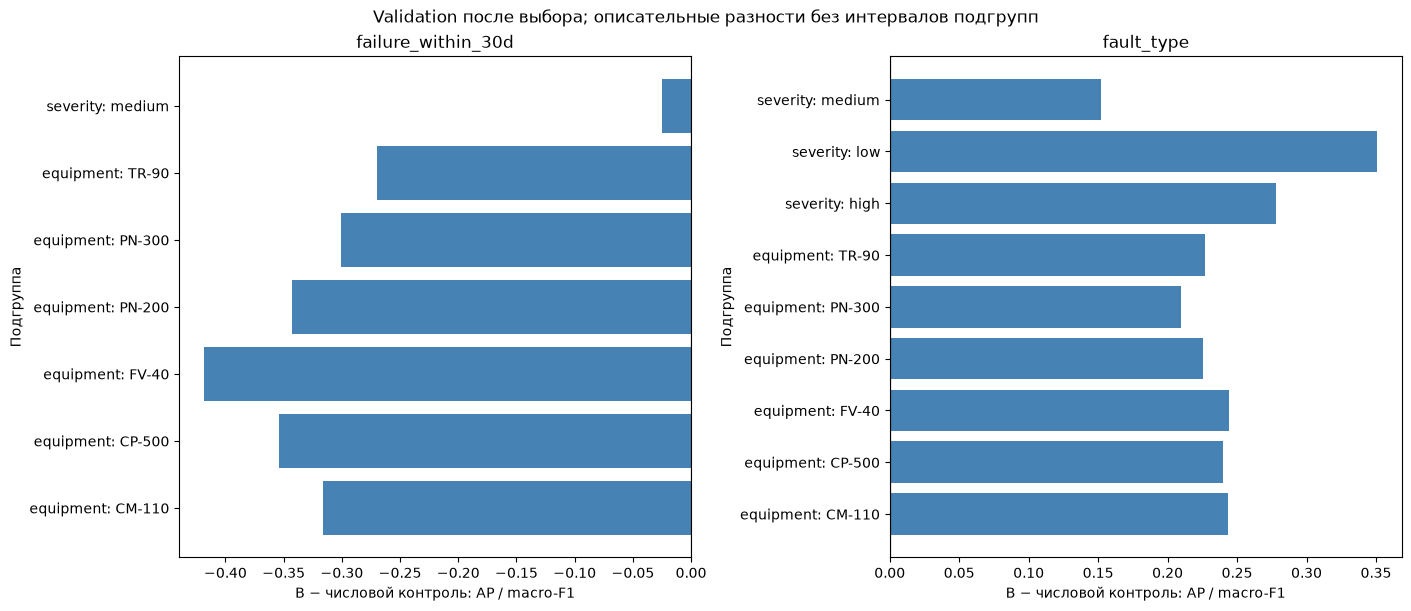

In [4]:
import matplotlib.pyplot as plt

figure, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
for axis, target, baseline in zip(
    axes,
    ["failure_within_30d", "fault_type"],
    ["catboost:A_numeric:failure_within_30d", "forest:A_numeric:fault_type"],
    strict=True,
):
    plot = differences.loc[differences["reference"].eq(baseline)]
    if target == "failure_within_30d":
        plot = plot.loc[
            plot["grouping"].ne("severity") | plot["value"].eq("medium")
        ]
    labels = plot["grouping"] + ": " + plot["value"].astype(str)
    axis.barh(labels, plot["difference"], color="steelblue")
    axis.axvline(0, color="black", linewidth=0.8)
    axis.set_title(target)
    axis.set_xlabel("B − числовой контроль: AP / macro-F1")
    axis.set_ylabel("Подгруппа")
figure.suptitle(
    "Validation после выбора; описательные разности без интервалов подгрупп"
)
figure.savefig(SUMMARY / "subgroup_differences.png", dpi=160)
plt.show()

## Передача сохранённых моделей участнику C и LLM/RAG

Шесть моделей: числовые A для двух целей, две TF-IDF и два B seed 42. Только train/validation. Метки лежат отдельно от входов и прогнозов; в LLM их передавать запрещено. Test не включена. Модели C/D здесь не строятся и не обучаются.

In [5]:
import shutil
import zipfile

HANDOFF = REVIEW_ROOT / REVIEW["output_root"] / "handoff"
if not (HANDOFF / "manifest.json").exists():
    HANDOFF.mkdir(exist_ok=True)
    allowed = [
        "equipment",
        "operating_hours",
        "temperature_c",
        "vibration_mm_s",
        "pressure_bar",
        "load_ratio",
        "operator_log",
        "manual_id",
        "horizon_days",
    ]
    for split, frame in [("train", train), ("validation", validation)]:
        frame[["id", *allowed]].to_csv(
            HANDOFF / (split + "_features.csv"), index=False
        )
        frame[["id", "failure_within_30d", "fault_type"]].to_csv(
            HANDOFF / (split + "_labels.csv"), index=False
        )
    development_ids.to_csv(HANDOFF / "development_membership.csv", index=False)
    manifest_models = []
    for spec in REVIEW["models"]:
        if spec["key"] not in REVIEW["handoff_model_keys"]:
            continue
        name = spec["key"].replace(":", "__")
        destination = HANDOFF / "models" / name
        destination.mkdir(parents=True, exist_ok=True)
        source = REVIEW_ROOT / spec["run_path"]
        if spec["family"] == "rubert":
            shutil.copytree(source / "model", destination / "model")
        else:
            shutil.copy2(source / "model.pkl", destination / "model.pkl")
            if spec["threshold"] is not None:
                shutil.copy2(
                    source / "model_f2.pkl", destination / "model_f2.pkl"
                )
        shutil.copy2(
            source / "manifest.json", destination / "source_manifest.json"
        )
        for split in ["train", "validation"]:
            predictions = pd.read_csv(source / (split + "_predictions.csv"))
            predictions.drop(columns=["y_true"]).to_csv(
                destination / (split + "_predictions_without_labels.csv"),
                index=False,
            )
        manifest_models.append(
            {
                **spec,
                "bundle_path": destination.relative_to(HANDOFF).as_posix(),
            }
        )
    shutil.copy2(REVIEW_ROOT / "pyproject.toml", HANDOFF / "pyproject.toml")
    shutil.copy2(REVIEW_ROOT / "uv.lock", HANDOFF / "uv.lock")
    shutil.copytree(
        REVIEW_ROOT / "src",
        HANDOFF / "src",
        ignore=shutil.ignore_patterns("__pycache__"),
    )
    (HANDOFF / "manifest.json").write_text(
        json.dumps(
            {
                "review_id": REVIEW["review_id"],
                "models": manifest_models,
                "test_rows_included": False,
                "fit_count": 0,
                "forbidden_features": [
                    "required_route",
                    "severity",
                    "failure_within_30d",
                    "fault_type",
                ],
                "label_files": "Только обучение/оценивание; не для LLM.",
            },
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )
print("Локальная передача:", HANDOFF.relative_to(REVIEW_ROOT))
display(
    pd.DataFrame(
        json.loads((HANDOFF / "manifest.json").read_text(encoding="utf-8"))[
            "models"
        ]
    )[["key", "bundle_path", "threshold"]]
)

Локальная передача: artifacts\experiments\ab_review_20261018T122826_185163Z\handoff


,key,bundle_path,threshold
0,logistic:T0_tfidf:failure_within_30d,models/logistic__T0_tfidf__failure_within_30d,0.143478
1,logistic:T0_tfidf:fault_type,models/logistic__T0_tfidf__fault_type,NaN
2,forest:A_numeric:fault_type,models/forest__A_numeric__fault_type,NaN
3,catboost:A_numeric:failure_within_30d,models/catboost__A_numeric__failure_within_30d,0.139186
4,rubert:B_text:failure_within_30d,models/rubert__B_text__failure_within_30d,0.130998
5,rubert:B_text:fault_type,models/rubert__B_text__fault_type,NaN


## Проверенные комментарии, итог A/B и локальный архив

30 индивидуальных комментариев проверены агентом по исходным строкам; человеческая проверка не заявляется. Итоговый отчёт различает AP и PR-AUC, особенности подгрупп и ограничения. Передача локальная, без внешней загрузки.

In [6]:
notes_path = REVIEW_ROOT / REVIEW["error_notes_file"]
assert (
    hashlib.sha256(notes_path.read_bytes()).hexdigest()
    == REVIEW["error_notes_sha256"]
)
notes = json.loads(notes_path.read_text(encoding="utf-8"))
assert set(notes["case_comments"]) == set(reviewed_errors["id"].astype(str))
annotated = reviewed_errors.copy()
annotated["case_comment"] = (
    annotated["id"].astype(str).map(notes["case_comments"])
)
annotated["review_status"] = "agent_content_checked"
annotated["human_reviewed"] = False
annotated_path = SUMMARY / "reviewed_errors_annotated.csv"
if not annotated_path.exists():
    annotated.to_csv(annotated_path, index=False)
case_text = [
    "# Содержательный разбор 30 ошибок A/B",
    "Validation, разные id. Подборка иллюстративная, "
    "не случайная оценка причин. "
    "Проверка выполнена агентом по исходным строкам и прогнозам; "
    "человеческая экспертная проверка не заявляется. "
    "Причинность и физические пороги по CSV не устанавливаются. "
    "Редкость — два наименьших класса train. "
    "Маршрутизация для A/B неприменима.",
]
for case in annotated.to_dict("records"):
    case_text.extend(
        [
            f"## id={case['id']}: {case['key']}",
            f"Категория: {case['category']}. {case['observation']}",
            f"Журнал: {case['operator_log']}",
            case["interpretation"],
            case["case_comment"],
        ]
    )
error_document = REVIEW_ROOT / "notebooks/experiments/AB_ERROR_ANALYSIS.md"
error_document.write_text("\n\n".join(case_text) + "\n", encoding="utf-8")

# 1) Добавить численность положительного класса к разностям подгрупп.
support = all_groups.loc[
    all_groups["key"].str.startswith("rubert:"),
    ["grouping", "value", "target", "positives"],
]
evaluable = differences.merge(
    support, on=["grouping", "value", "target"], validate="many_to_one"
)
evaluable["both_binary_classes"] = np.where(
    evaluable["target"].eq("failure_within_30d"),
    evaluable["positives"].gt(0)
    & evaluable["positives"].lt(evaluable["records"]),
    False,
)
if not (SUMMARY / "subgroup_differences_with_support.csv").exists():
    evaluable.to_csv(
        SUMMARY / "subgroup_differences_with_support.csv", index=False
    )

# 2) Сформировать итог без изменения выбранных моделей и порогов.
result_text = [
    "# A/B: итог анализа перед передачей команде",
    f"Закреплённый разбор: `{REVIEW['output_root']}`. "
    "16 выбранных моделей, ноль новых исследовательских fit; "
    "test не оценивалась. C и LLM/RAG выполняет другой участник.",
    "## Основные результаты validation",
]
for key in REVIEW["handoff_model_keys"]:
    rows = all_metrics.loc[all_metrics["key"].eq(key)]
    row = (
        rows.loc[rows["rule"].eq("f2")].iloc[0]
        if "failure" in key
        else rows.iloc[0]
    )
    if "failure" in key:
        description = (
            f"AP={row['average_precision']:.6f}; "
            f"PR-AUC (трапеции)={row['pr_auc_trapezoid']:.6f}; "
            f"ROC-AUC={row['roc_auc']:.6f}; "
            f"precision/recall={row['precision']:.6f}/{row['recall']:.6f}; "
            f"F1/F2={row['f1']:.6f}/{row['f2']:.6f}."
        )
    else:
        description = f"macro-F1={row['macro_f1']:.6f}."
    result_text.append(f"- `{key}`: {description}")
result_text.extend(
    [
        "AP — сумма precision по приращениям recall; PR-AUC здесь "
        "отдельная площадь с трапецеидальной интерполяцией. Обе вычислены "
        "по исходным сохранённым вероятностям. "
        "Выбор моделей по AP не менялся.",
        "## Подгруппы и редкость",
        "Полная таблица: `summary/subgroup_differences_with_support.csv` "
        "в каталоге разбора. Все сравнения выровнены по одним id; "
        "отдельные интервалы подгрупп не рассчитывались. "
        "Макроусреднение диагноза сохраняет общий набор шести классов: "
        "отсутствующий класс с неопределённым F1 получает 0. Поэтому "
        "идеальная классификация подгруппы не всегда означает macro-F1=1.",
        "Для отказа B уступает числовому CatBoost во всех шести equipment. "
        "Наибольшая разность AP B−CatBoost: FV-40, −0.418783, n=372; "
        "наименьшая потеря среди equipment: TR-90, −0.270113, n=396. "
        "Относительно TF-IDF разность меняет знак: от −0.020212 "
        "на TR-90 до +0.023368 на PN-300; это описательные оценки, "
        "а не установленное преимущество в отдельных группах.",
        "В severity=high все 135 объектов — отказы: AP=1 "
        "не позволяет сравнить ранжирование. В severity=low все 1 536 "
        "объектов отрицательные: AP/ROC-AUC неопределены. "
        "В medium есть оба класса (228/522 отказов); AP B−CatBoost "
        "равна −0.024859. Нельзя объявлять high группой равного "
        "качества моделей на основании AP=1.",
        "Для диагноза B и TF-IDF дают одинаковые идеальные прогнозы "
        "во всех подгруппах; разность B−TF-IDF равна нулю. "
        "По сравнению с числовым RF прирост F1 по классам: "
        "seal_leak +0.440181, imbalance +0.349593, "
        "bearing_wear +0.278826, cavitation +0.150562, "
        "normal +0.105523, overheat +0.049900. "
        "Самый малочисленный cavitation не имеет наибольшего прироста: "
        "простая монотонная связь с редкостью не подтверждается.",
        "## Ошибки",
        "[Разобраны 30 разных объектов](AB_ERROR_ANALYSIS.md): "
        "18 ошибок отказа (9 FN и 9 FP) и 12 ошибок диагноза. "
        "Есть пограничные вероятности, FP выше 0.5, ошибки редких "
        "классов и пересекающиеся сенсорные диапазоны. "
        "Шаблон журнала определён только по train. Числовой прогноз, "
        "расходящийся с журналом, не означает противоречивость "
        "самого журнала или ошибку данных. Причины остаются гипотезами; "
        "ошибки маршрутизации исследует компонент другого участника.",
        "## Время и архитектура",
        "B — компактный русскоязычный BertForSequenceClassification, "
        "три слоя, hidden_size=312, 12 голов внимания. "
        "Полное дообучение проверяет пользу адаптации кодировщика, "
        "две головы обучаются независимо. max_length=128 проверена "
        "по train без усечения (максимум 20 токенов); изменение "
        "ограничения по test не выполнялось. Компактный кодировщик "
        "позволил выполнить протокол на CPU. Эти основания не доказывают "
        "оптимальность архитектуры: сравнения других кодировщиков не было.",
        "Время применения: тёплый CPU, до шести потоков (RF — "
        "сохранённый n_jobs=1), пакеты 64, пять повторов всего validation. "
        "Одиночные запросы — первые 64 объекта, три повтора; приведено "
        "среднее на запрос в медианной серии, не p95. Предобработка "
        "включена; загрузка весов/диск/сеть исключены. "
        "Историческое время обучения относится к выбранному кандидату, "
        "а не полному поиску. Память и денежная стоимость не измерены.",
    ]
)
for row in all_timings.loc[
    all_timings["key"].isin(REVIEW["handoff_model_keys"])
].to_dict("records"):
    result_text.append(
        f"- `{row['key']}`: fit {row['fit_seconds']:.3f} с; "
        "пакетное применение 2 193 строк "
        f"{row['batch_median_seconds']:.4f} с; "
        f"одиночный запрос в среднем {row['single_mean_request_ms']:.3f} мс."
    )
result_text.extend(
    [
        "## Отрицательные результаты и выводы",
        "1. Числовой CatBoost остаётся самым сильным проверенным "
        "числовым решением отказа по validation AP; B не заменяет его.",
        "2. Диагноз из повторяемых текстов легко решается TF-IDF. "
        "Равный результат B не доказывает пользу сложности трансформера.",
        "3. AP B−TF-IDF=+0.008111, групповой 95%-й интервал "
        "[−0.012195; 0.028519] исходного опыта включает ноль. "
        "По equipment разность меняет знак; установленного преимущества нет.",
        "4. F2 повышает полноту ценой ложных тревог; часть FP "
        "возникает и выше порога 0.5. Ни диагноз, ни вероятность "
        "не являются детерминированной гарантией будущего отказа.",
        "5. Идеальная validation не означает устойчивости формулировок: "
        "на 24 одобренных синтетических вариантах диагноз верен "
        "в 18/24 у TF-IDF и 22/24, 17/24, 22/24 у B seeds 42/17/123. "
        "Это небольшая зависимая проверка шести источников, не новая test.",
        "6. Выигрыш текста над числами в диагнозе не монотонен "
        "по редкости классов; особенно полезен текст для seal_leak "
        "и imbalance. Это польза информации, не доказательство "
        "превосходства архитектуры B над TF-IDF.",
        "7. B существенно дороже TF-IDF по обучению и пакетному "
        "применению на этой машине. Для текущей текстовой задачи "
        "измеренный выигрыш такую сложность пока не оправдывает.",
        "8. H1 не получила общего подтверждения; H2 и H3 "
        "должен проверить участник C/RAG. H4 исследована описательно; "
        "новых причинных или статистических выводов по подгруппам нет.",
        "## Передача и итоговая test",
        "[Инструкция передачи](AB_HANDOFF.md). Набор: "
        f"`{REVIEW['output_root']}/handoff`; ZIP: "
        f"`{REVIEW['output_root']}/ab_handoff.zip`. "
        "Шесть моделей, отдельные train/validation входы и метки, "
        "прогнозы без y_true, классы, конфигурации, исходные веса "
        "и токенизаторы. Представления для C не рассчитывались; "
        "способ их получения и правила обучения выбирает участник C.",
        "[Протокол](../../configs/final_evaluation_protocol.json) "
        "фиксирует A/B и оставляет C/D для будущей фиксации участником. "
        "Это не утверждение, что протокол уже согласован им. "
        "Test не оценена; после фиксации всех систем нужен общий "
        "однократный итоговый расчёт без настройки по test. "
        "Существующие оценки/интервалы получены после выбора "
        "на одной validation и могут быть оптимистичными.",
        "## Воспроизводимость и вклад",
        "Новые разделы ab-review четырёх существующих тетрадей и "
        "ab-summary тетради B выполнены в свежих ядрах .venv. "
        "Исходные обучение и поиск повторно не выполнялись. "
        "Вероятности всех 16 загруженных моделей совпали "
        "с сохранёнными в пределах atol=1e-6, rtol=1e-5. "
        "Предыдущие версии тетрадей сохранены в source_notebooks "
        "каталога разбора. Полный Run All старых обучающих тетрадей "
        "не выполнялся и может запускать обучение.",
        "Этот этап реализации и разбора выполнен агентом "
        "по поручению пользователя; распределение A/B и C/LLM/RAG "
        "подтверждено пользователем. Личные имена и фактический "
        "вклад остальных участников не выдумываются. "
        "Переносимый набор ещё не запускался на чужой машине.",
    ]
)
(REVIEW_ROOT / "notebooks/experiments/AB_RESULTS.md").write_text(
    "\n\n".join(result_text) + "\n", encoding="utf-8"
)

# 3) Завершить локальный набор и записать контрольные суммы архива.
for filename in ["ab_review.json", "final_evaluation_protocol.json"]:
    shutil.copy2(REVIEW_ROOT / "configs" / filename, HANDOFF / filename)
(HANDOFF / "README.md").write_text(
    "# Передача A/B\n\n"
    "Это набор для загрузки готовых моделей и обучения C, "
    "не полная копия всех исторических экспериментов.\n\n"
    "Входы лежат в *_features.csv, цели — отдельно в *_labels.csv. "
    "Не передавать метки в LLM. Test и запрещённые признаки "
    "не включены во входы. Классы, пороги, входы и пути моделей "
    "указаны в manifest.json. Зависимости: pyproject.toml и uv.lock; "
    "установка CPU через uv sync --locked --extra transformer. "
    "Сборка на другой машине ещё не проверялась.\n\n"
    "C/LLM/RAG и общее test-оценивание здесь не выполнялись. "
    "Перед test дополнить final_evaluation_protocol.json "
    "фиксацией C/D. Полный разбор и инструкция передачи находятся "
    "в основном репозитории: notebooks/experiments/AB_RESULTS.md "
    "и AB_HANDOFF.md.\n",
    encoding="utf-8",
)
bundle_files = {
    file.relative_to(HANDOFF).as_posix(): hashlib.sha256(
        file.read_bytes()
    ).hexdigest()
    for file in HANDOFF.rglob("*")
    if file.is_file() and file.name != "checksums.json"
}
(HANDOFF / "checksums.json").write_text(
    json.dumps(bundle_files, indent=2), encoding="utf-8"
)
archive = HANDOFF.parent / "ab_handoff.zip"
if not archive.exists():
    with zipfile.ZipFile(
        archive, "w", compression=zipfile.ZIP_DEFLATED
    ) as bundle:
        for file in HANDOFF.rglob("*"):
            if file.is_file():
                bundle.write(file, file.relative_to(HANDOFF).as_posix())
print(
    "Архив", archive.relative_to(REVIEW_ROOT), archive.stat().st_size, "байт"
)
print(
    "Ошибок разобрано:",
    len(annotated),
    "различных id:",
    annotated["id"].nunique(),
)
display(evaluable.loc[evaluable["target"].eq("failure_within_30d")])

Архив artifacts\experiments\ab_review_20261018T122826_185163Z\ab_handoff.zip 221767779 байт
Ошибок разобрано: 30 различных id: 30


,target,metric,reference,grouping,value,records,reference_score,b_score,difference,positives,both_binary_classes
0,failure_within_30d,average_precision,logistic:A_numeric:failure_within_30d,equipment,CM-110,344,0.689903,0.444384,-0.245519,57.0,True
1,failure_within_30d,average_precision,logistic:A_numeric:failure_within_30d,equipment,CP-500,319,0.721190,0.504117,-0.217073,55.0,True
2,failure_within_30d,average_precision,logistic:A_numeric:failure_within_30d,equipment,FV-40,372,0.755409,0.387408,-0.368001,51.0,True
3,failure_within_30d,average_precision,logistic:A_numeric:failure_within_30d,equipment,PN-200,367,0.706389,0.446330,-0.260059,58.0,True
4,failure_within_30d,average_precision,logistic:A_numeric:failure_within_30d,equipment,PN-300,395,0.641945,0.467501,-0.174444,75.0,True
...,...,...,...,...,...,...,...,...,...,...,...
58,failure_within_30d,average_precision,catboost:A_tabular_restricted:failure_within_30d,equipment,PN-300,395,0.776923,0.467501,-0.309422,75.0,True
59,failure_within_30d,average_precision,catboost:A_tabular_restricted:failure_within_30d,equipment,TR-90,396,0.770294,0.497899,-0.272395,67.0,True
60,failure_within_30d,average_precision,catboost:A_tabular_restricted:failure_within_30d,severity,high,135,1.000000,1.000000,0.000000,135.0,False
61,failure_within_30d,average_precision,catboost:A_tabular_restricted:failure_within_30d,severity,low,1536,NaN,NaN,NaN,0.0,False


In [7]:
import joblib

# 1) Скопировать текущий код и сводки в переносимый набор.
shutil.copytree(
    REVIEW_ROOT / "src",
    HANDOFF / "src",
    dirs_exist_ok=True,
    ignore=shutil.ignore_patterns("__pycache__"),
)
(HANDOFF / "results").mkdir(exist_ok=True)
for filename in [
    "metrics.csv",
    "subgroup_differences_with_support.csv",
    "class_differences.csv",
    "timings.csv",
]:
    shutil.copy2(SUMMARY / filename, HANDOFF / "results" / filename)
guide = (REVIEW_ROOT / "notebooks/experiments/AB_HANDOFF.md").read_text(
    encoding="utf-8"
)
guide = guide.replace("[AB_RESULTS.md](AB_RESULTS.md)", "`results/`")
guide = guide.replace(
    "../../configs/final_evaluation_protocol.json",
    "final_evaluation_protocol.json",
)
(HANDOFF / "HANDOFF_SOURCE_GUIDE.md").write_text(guide, encoding="utf-8")

# 2) Загрузить именно копии моделей, исключив метки из входов.
bundle_manifest = json.loads(
    (HANDOFF / "manifest.json").read_text(encoding="utf-8")
)
bundle_validation = pd.read_csv(
    HANDOFF / "validation_features.csv", dtype={"id": "string"}
)
bundle_checks = []
for specification in bundle_manifest["models"]:
    local_spec = specification.copy()
    local_spec["run_path"] = local_spec["bundle_path"]
    predict, classes = load_cpu_predictor(
        HANDOFF, local_spec, REVIEW["cpu_threads"]
    )
    features = bundle_validation[local_spec["features"]]
    with threadpool_limits(limits=REVIEW["cpu_threads"]):
        actual, _ = time_predictions(
            predict, features, REVIEW["batch_size"], 1
        )
    directory = HANDOFF / local_spec["bundle_path"]
    golden = (
        pd.read_csv(
            directory / "validation_predictions_without_labels.csv",
            dtype={"id": "string"},
        )
        .set_index("id")
        .loc[bundle_validation["id"]]
    )
    expected = golden[[f"probability_{label}" for label in classes]]
    np.testing.assert_allclose(
        actual,
        expected,
        atol=REVIEW["prediction_atol"],
        rtol=REVIEW["prediction_rtol"],
    )
    threshold_checked = False
    if local_spec["threshold"] is not None:
        binary_labels = actual[:, classes.index(1)] >= local_spec["threshold"]
        source_predictions = (
            pd.read_csv(
                REVIEW_ROOT
                / specification["run_path"]
                / "validation_predictions_f2.csv",
                dtype={"id": "string"},
            )
            .set_index("id")
            .loc[bundle_validation["id"]]
        )
        np.testing.assert_array_equal(
            binary_labels, source_predictions["y_pred"]
        )
        if local_spec["family"] != "rubert":
            wrapped = joblib.load(directory / "model_f2.pkl")
            wrapped_inputs = (
                features["operator_log"]
                if local_spec["features"] == ["operator_log"]
                else features
            )
            np.testing.assert_array_equal(
                wrapped.predict(wrapped_inputs), binary_labels
            )
        threshold_checked = True
    else:
        labels = np.asarray(classes)[actual.argmax(axis=1)]
        np.testing.assert_array_equal(labels, golden["y_pred"])
    bundle_checks.append(
        {
            "key": local_spec["key"],
            "probabilities_match": True,
            "labels_match": True,
            "f2_rule_checked": threshold_checked,
        }
    )
    del predict

# 3) Пересобрать архив только текущей передачи и проверить содержимое.
checksums = {
    file.relative_to(HANDOFF).as_posix(): hashlib.sha256(
        file.read_bytes()
    ).hexdigest()
    for file in HANDOFF.rglob("*")
    if file.is_file() and file.name != "checksums.json"
}
(HANDOFF / "checksums.json").write_text(
    json.dumps(checksums, indent=2), encoding="utf-8"
)
archive = HANDOFF.parent / "ab_handoff.zip"
with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for file in HANDOFF.rglob("*"):
        if file.is_file():
            bundle.write(file, file.relative_to(HANDOFF).as_posix())
with zipfile.ZipFile(archive) as bundle:
    assert bundle.testzip() is None
    for name, digest in checksums.items():
        assert hashlib.sha256(bundle.read(name)).hexdigest() == digest
(SUMMARY / "handoff_verification.json").write_text(
    json.dumps(
        {
            "models": bundle_checks,
            "test_rows_included": False,
            "archive_bytes": archive.stat().st_size,
            "archive_sha256": hashlib.sha256(archive.read_bytes()).hexdigest(),
            "archive_files_checked": len(checksums),
            "external_machine_tested": False,
        },
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)
display(pd.DataFrame(bundle_checks))
print("Проверен локальный архив:", archive.relative_to(REVIEW_ROOT))

C:\Users\Mo\work\study\Магистратура\2к\1с\LLMs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,key,probabilities_match,labels_match,f2_rule_checked
0,logistic:T0_tfidf:failure_within_30d,True,True,True
1,logistic:T0_tfidf:fault_type,True,True,False
2,forest:A_numeric:fault_type,True,True,False
3,catboost:A_numeric:failure_within_30d,True,True,True
4,rubert:B_text:failure_within_30d,True,True,True
5,rubert:B_text:fault_type,True,True,False


Проверен локальный архив: artifacts\experiments\ab_review_20261018T122826_185163Z\ab_handoff.zip
